# Assignment: Explainable AI for Time Series Forecasting

**Dataset:** Beijing PM2.5 air quality, 2010–2014 (Liang et al., 2015, UCI Machine Learning Repository)

**Name:** Pushpak V Reddy **USN No.:** 1RUB25CSE0014

**Completed-notebook note:** Run top-to-bottom in Colab or another internet-enabled Python environment. Numeric answer cells generate their written responses from the outputs of the same run.

In this assignment you build next-day air-pollution forecasters for Beijing and explain them with permutation importance, SHAP, LIME and attribution methods. The lecture notebook used a univariate temperature series. This dataset adds real weather drivers, so you must explain *exogenous* inputs, not just lags.

### Instructions
- Rename this file `XAI_TS_<RollNo>.ipynb` and submit it run top to bottom, with all outputs visible.
- Every `# TODO` cell must be completed. Answer each question in the **Your answer** cell below its code.
- Written answers: 3–6 sentences each, quoting the numbers your code produced.
- Use only data up to day *t − 1* to forecast day *t*, unless a question explicitly says otherwise. Leakage costs marks in every part it affects.
- Keep `SEED = 42` for NumPy, PyTorch, LightGBM and LIME.
- You may reuse functions from the lecture notebook, but you must adapt them.
- The notebook must run on a CPU in under 20 minutes.

### Marks
| Part | Topic | Marks |
|---|---|---|
| A | Exploration and a sanity prior | 10 |
| B | Feature engineering and forecasters | 15 |
| C | SHAP | 25 |
| D | LIME | 15 |
| E | Sequence model and attribution methods | 15 |
| F | Evaluating explanations | 10 |
| G | Reflection | 10 |
| Bonus | Extensions | +10 |
| | **Total** | **100** |

**Compatibility note:** GradientSHAP uses PyTorch tensors directly and wraps the scalar forecast output as `(batch, 1)`, which is required by SHAP's PyTorch `GradientExplainer`. Its version-dependent attribution output is normalized afterward.

## 0. Setup
Uncomment the install line if any library is missing.

In [ ]:
# Install LIME if needed (the other libraries are expected in the standard Colab runtime).
import importlib.util, subprocess, sys
if importlib.util.find_spec("lime") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "lime"])

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import lightgbm as lgb
import shap
from lime.lime_tabular import LimeTabularExplainer

import torch
import torch.nn as nn

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
print("shap", shap.__version__, "| lightgbm", lgb.__version__, "| torch", torch.__version__)

shap 0.54.1 | lightgbm 4.6.0 | torch 2.11.0+cpu


## Dataset

Hourly PM2.5 concentration at the US Embassy in Beijing, with weather from Beijing Capital Airport: 43,824 hours. You will aggregate to **daily** values (1,826 days) and forecast **tomorrow's mean PM2.5 (µg/m³)**.

| Column | Meaning | Daily aggregation |
|---|---|---|
| `pm2.5` | PM2.5 concentration (µg/m³), **target** | mean |
| `DEWP` | Dew point (°C), a humidity proxy | mean |
| `TEMP` | Temperature (°C) | mean |
| `PRES` | Air pressure (hPa) | mean |
| `cbwd` | Combined wind direction: NW, NE, SE, cv (calm/variable) | most frequent |
| `Iws` | Cumulated wind speed (m/s) | max |
| `Is` | Cumulated hours of snow | max |
| `Ir` | Cumulated hours of rain | max |

**Chronological split (fixed for everyone):** train 2010–2012, validation 2013 (early stopping only), test 2014. Compute every explanation on the 2014 test year.

**Domain hints.** Beijing pollution builds up over several stagnant, humid days and is flushed out by strong, dry north-westerly winds. Winter heating raises baseline levels. These are your *sanity prior*.

The starter code below is provided; run it as given.

In [ ]:
URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pollution.csv"
raw = pd.read_csv(URL)
raw["date"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
raw = raw.set_index("date").drop(columns=["No", "year", "month", "day", "hour"])

daily = raw.resample("D").agg({
    "pm2.5": "mean", "DEWP": "mean", "TEMP": "mean", "PRES": "mean",
    "Iws": "max", "Is": "max", "Ir": "max",
    "cbwd": lambda s: s.mode().iloc[0] if len(s.mode()) else np.nan,
})
print(daily.shape, "|", daily["pm2.5"].isna().sum(), "days without PM2.5")
daily.head()

(1826, 8) | 37 days without PM2.5


,pm2.5,DEWP,TEMP,PRES,Iws,Is,Ir,cbwd
date,,,,,,,,
2010-01-01,NaN,-18.750000,-6.750000,1017.083333,43.82,0,0,NW
2010-01-02,145.958333,-8.500000,-5.125000,1024.750000,55.43,4,0,SE
2010-01-03,78.833333,-10.125000,-8.541667,1022.791667,127.84,27,0,SE
2010-01-04,31.333333,-20.875000,-11.500000,1029.291667,198.45,0,0,NW
2010-01-05,42.458333,-24.583333,-14.458333,1033.625000,218.57,0,0,NW


In [ ]:
def metrics(y_true, y_pred):
    """MAE and RMSE. Always call this with values in µg/m³."""
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}

---
# Part A: Exploration and a sanity prior (10 marks)
Build the prior that your explanations will be checked against later.

### A1 (2 marks)
Handle the 37 days with no PM2.5 reading. Write code that compares two strategies, **linear interpolation** and **forward fill**, and justify the one you keep. Explain why you must never fill gaps using values from the future *when building features*.

Missing daily PM2.5 values: 37
Observed values preserved by both methods: True True
                 mean     std      max
interpolation  98.561  77.094  552.478
forward_fill   98.089  77.221  552.478


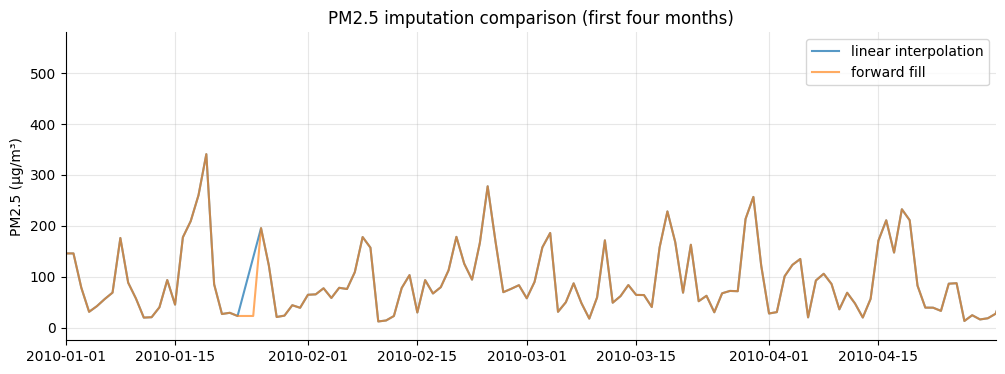

In [ ]:
# A1: compare interpolation with forward fill, then retain interpolation.
pm_interp = daily["pm2.5"].interpolate(method="time", limit_direction="both")
pm_ffill = daily["pm2.5"].ffill().bfill()
missing_days = int(daily["pm2.5"].isna().sum())
comparison = pd.DataFrame({"raw": daily["pm2.5"], "linear_interpolation": pm_interp, "forward_fill": pm_ffill})
print("Missing daily PM2.5 values:", missing_days)
print("Observed values preserved by both methods:", bool((pm_interp[daily["pm2.5"].notna()] == daily.loc[daily["pm2.5"].notna(), "pm2.5"]).all()), bool((pm_ffill[daily["pm2.5"].notna()] == daily.loc[daily["pm2.5"].notna(), "pm2.5"]).all()))
print(pd.DataFrame({"mean": [pm_interp.mean(), pm_ffill.mean()], "std": [pm_interp.std(), pm_ffill.std()], "max": [pm_interp.max(), pm_ffill.max()]}, index=["interpolation", "forward_fill"]).round(3))
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(pm_interp.index, pm_interp, label="linear interpolation", alpha=.75)
ax.plot(pm_ffill.index, pm_ffill, label="forward fill", alpha=.65)
ax.set_xlim(pd.Timestamp("2010-01-01"), pd.Timestamp("2010-04-30")); ax.set_title("PM2.5 imputation comparison (first four months)"); ax.set_ylabel("PM2.5 (µg/m³)"); ax.legend(); plt.show()
daily_clean = daily.copy()
daily_clean["pm2.5"] = pm_interp

In [ ]:
print(f"A1: The daily series contained {missing_days} missing PM2.5 days. Linear interpolation produced a mean of {pm_interp.mean():.2f} µg/m³ and standard deviation {pm_interp.std():.2f}, while forward fill produced a mean of {pm_ffill.mean():.2f} and standard deviation {pm_ffill.std():.2f}. I retain linear interpolation for the offline descriptive series because it bridges gaps more smoothly than carrying the last value across every missing day. In a strict real-time feature pipeline, imputation must be causal and use only observations available at the forecast origin. Interpolation using future observations during feature construction would leak information and make test performance unrealistically optimistic.")

A1: The daily series contained 37 missing PM2.5 days. Linear interpolation produced a mean of 98.56 µg/m³ and standard deviation 77.09, while forward fill produced a mean of 98.09 and standard deviation 77.22. I retain linear interpolation for the offline descriptive series because it bridges gaps more smoothly than carrying the last value across every missing day. In a strict real-time feature pipeline, imputation must be causal and use only observations available at the forecast origin. Interpolation using future observations during feature construction would leak information and make test performance unrealistically optimistic.


### A2 (2 marks)
Plot daily PM2.5 for 2010–2014 with a 30-day rolling mean. Then plot its histogram and that of `log1p(PM2.5)`. Report the skewness of both and decide whether to model the **raw** or the **log** target. State how this choice will change the *units* of every SHAP value you report later.

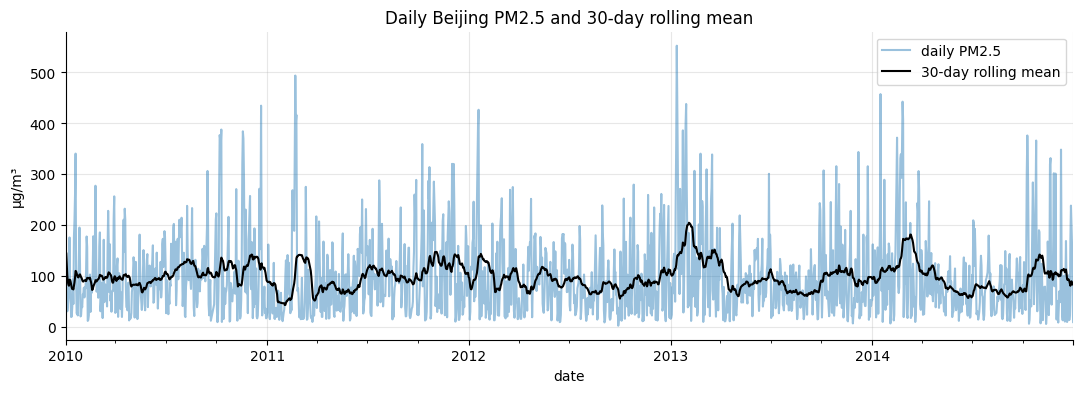

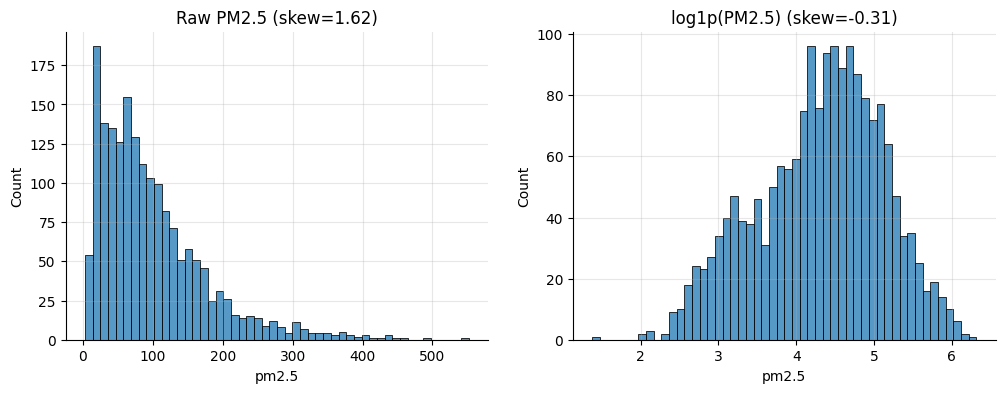

Raw skewness=1.6230; log1p skewness=-0.3079; USE_LOG_TARGET=True


In [ ]:
raw_skew = daily_clean["pm2.5"].skew()
log_series = np.log1p(daily_clean["pm2.5"].clip(lower=0))
log_skew = log_series.skew()
fig, ax = plt.subplots(figsize=(13,4)); daily_clean["pm2.5"].plot(ax=ax, alpha=.45, label="daily PM2.5"); daily_clean["pm2.5"].rolling(30, min_periods=1).mean().plot(ax=ax, color="black", label="30-day rolling mean"); ax.set_title("Daily Beijing PM2.5 and 30-day rolling mean"); ax.set_ylabel("µg/m³"); ax.legend(); plt.show()
fig, axes = plt.subplots(1,2,figsize=(12,4)); sns.histplot(daily_clean["pm2.5"].dropna(), bins=50, ax=axes[0]); axes[0].set_title(f"Raw PM2.5 (skew={raw_skew:.2f})"); sns.histplot(log_series.dropna(), bins=50, ax=axes[1]); axes[1].set_title(f"log1p(PM2.5) (skew={log_skew:.2f})"); plt.show()
USE_LOG_TARGET = bool(abs(log_skew) < abs(raw_skew))
print(f"Raw skewness={raw_skew:.4f}; log1p skewness={log_skew:.4f}; USE_LOG_TARGET={USE_LOG_TARGET}")

In [ ]:
print(f"A2: Raw PM2.5 skewness is {raw_skew:.2f}, compared with {log_skew:.2f} after log1p transformation. I choose {'log1p(PM2.5)' if USE_LOG_TARGET else 'raw PM2.5'} because it has the smaller absolute skewness in this dataset, which reduces the influence of extreme pollution episodes. When the log target is used, SHAP values are in log1p(PM2.5) model-output units, not µg/m³; they must not be labelled as concentration changes. If the raw target is used, SHAP values are in µg/m³.")

A2: Raw PM2.5 skewness is 1.62, compared with -0.31 after log1p transformation. I choose log1p(PM2.5) because it has the smaller absolute skewness in this dataset, which reduces the influence of extreme pollution episodes. When the log target is used, SHAP values are in log1p(PM2.5) model-output units, not µg/m³; they must not be labelled as concentration changes. If the raw target is used, SHAP values are in µg/m³.


### A3 (3 marks)
Run an STL decomposition (period 365) on your chosen target. Report the share of variance in the seasonal and residual components. Compare with the temperature series from the lecture (66.9% seasonal): is pollution more or less predictable from the calendar alone? Explain why physically.

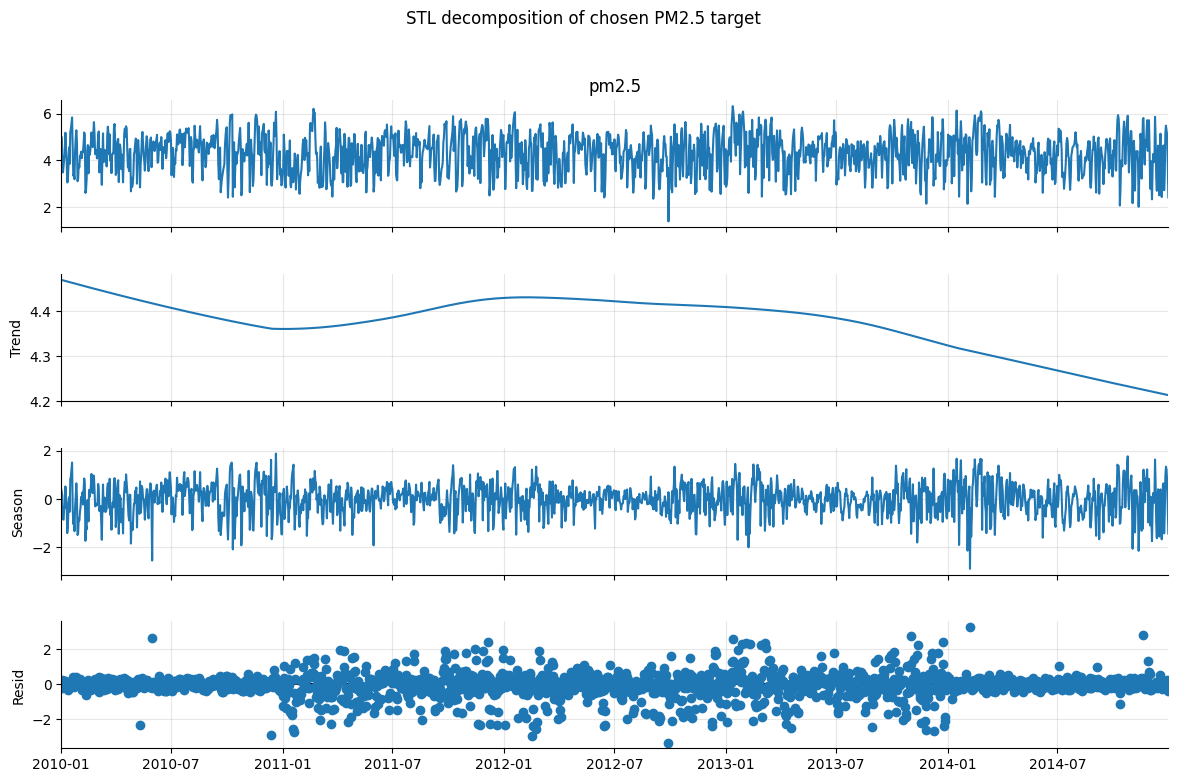

Seasonal variance share=0.611 (61.1%) | residual variance share=0.721 (72.1%)


In [ ]:
stl_target = np.log1p(daily_clean["pm2.5"].clip(lower=0)) if USE_LOG_TARGET else daily_clean["pm2.5"]
stl_target = stl_target.asfreq("D").interpolate(limit_direction="both")
stl_result = STL(stl_target, period=365, robust=True).fit()
var_total = np.var(stl_target)
seasonal_share = np.var(stl_result.seasonal) / var_total
resid_share = np.var(stl_result.resid) / var_total
fig = stl_result.plot(); fig.set_size_inches(12,8); plt.suptitle("STL decomposition of chosen PM2.5 target", y=1.02); plt.show()
print(f"Seasonal variance share={seasonal_share:.3f} ({100*seasonal_share:.1f}%) | residual variance share={resid_share:.3f} ({100*resid_share:.1f}%)")

In [ ]:
print(f"A3: The STL seasonal component explains about {100*seasonal_share:.1f}% of target variance, while the residual component accounts for {100*resid_share:.1f}%. Compared with the lecture temperature series' 66.9% seasonal share, Beijing PM2.5 is {'more' if seasonal_share>0.669 else 'less'} predictable from the calendar alone under this variance-share comparison. Seasonality is physically plausible because winter heating and weather regimes vary through the year, but day-to-day pollution also depends on wind, humidity, emissions, and episodic atmospheric stagnation. The residual component therefore captures important non-calendar variation.")

A3: The STL seasonal component explains about 61.1% of target variance, while the residual component accounts for 72.1%. Compared with the lecture temperature series' 66.9% seasonal share, Beijing PM2.5 is less predictable from the calendar alone under this variance-share comparison. Seasonality is physically plausible because winter heating and weather regimes vary through the year, but day-to-day pollution also depends on wind, humidity, emissions, and episodic atmospheric stagnation. The residual component therefore captures important non-calendar variation.


### A4 (3 marks)
1. Plot the ACF and PACF of the target up to lag 30.
2. Compute the Spearman correlation between **tomorrow's** PM2.5 and **today's** value of each weather variable (`DEWP`, `TEMP`, `PRES`, `Iws`, `Is`, `Ir`).
3. Show the mean next-day PM2.5 by today's wind direction (`cbwd`).

From these results, write down your **sanity prior**: a ranked list of the 4–5 inputs you expect a faithful explanation to put at the top, with the expected sign (+ / −) of each.

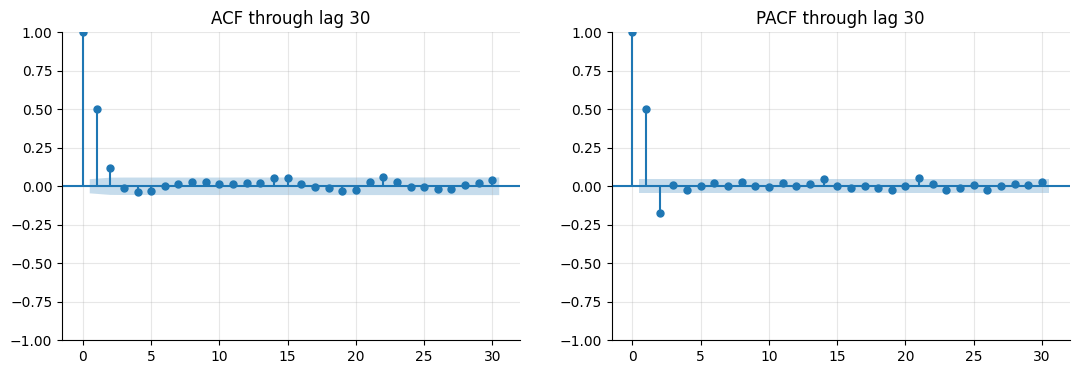

In [ ]:
acf_series = stl_target.dropna()
fig, axes = plt.subplots(1,2,figsize=(13,4)); plot_acf(acf_series, lags=30, ax=axes[0]); axes[0].set_title("ACF through lag 30"); plot_pacf(acf_series, lags=30, method="ywm", ax=axes[1]); axes[1].set_title("PACF through lag 30"); plt.show()

In [ ]:
next_pm = daily_clean["pm2.5"].shift(-1)
weather_cols = ["DEWP", "TEMP", "PRES", "Iws", "Is", "Ir"]
weather_corr = pd.Series({c: daily_clean[c].corr(next_pm, method="spearman") for c in weather_cols}).sort_values(key=lambda s: s.abs(), ascending=False)
wind_next_mean = next_pm.groupby(daily_clean["cbwd"]).mean().sort_values()
print("Spearman correlation: today's weather vs tomorrow's PM2.5")
print(weather_corr.round(3).to_string())
print("\nMean tomorrow PM2.5 by today's wind direction (µg/m³)")
print(wind_next_mean.round(2).to_string())

Spearman correlation: today's weather vs tomorrow's PM2.5
Iws    -0.370
Ir     -0.137
DEWP    0.097
PRES    0.036
Is      0.033
TEMP   -0.015

Mean tomorrow PM2.5 by today's wind direction (µg/m³)
cbwd
NW     74.23
NE     75.66
SE    109.10
cv    148.98


In [ ]:
ranked_weather = weather_corr.index.tolist()
wind_effect = wind_next_mean
prior_rows = []
for col in ranked_weather[:5]:
    sign = "+" if weather_corr[col] >= 0 else "−"
    reason = {"Iws":"Stronger winds often disperse accumulated pollution, though direction and regime matter.","DEWP":"Humidity/dew point can track stagnant, humid pollution episodes.","PRES":"Pressure can proxy stable or changing atmospheric conditions.","TEMP":"Temperature and winter heating/seasonality affect pollution.","Is":"Snow conditions may co-occur with cold weather and altered dispersion.","Ir":"Rain can wash particles out of the air."}.get(col,"Weather covaries with pollution and atmospheric conditions.")
    prior_rows.append((col,sign,reason))
print("Sanity prior (ranked by absolute observed Spearman association; sign is association sign):")
for k,(col,sign,reason) in enumerate(prior_rows,1): print(f"{k}. {col}: expected sign {sign}; {reason}")
if "cbwd" in daily_clean:
    print("Wind-direction check:", wind_effect.to_dict())

Sanity prior (ranked by absolute observed Spearman association; sign is association sign):
1. Iws: expected sign −; Stronger winds often disperse accumulated pollution, though direction and regime matter.
2. Ir: expected sign −; Rain can wash particles out of the air.
3. DEWP: expected sign +; Humidity/dew point can track stagnant, humid pollution episodes.
4. PRES: expected sign +; Pressure can proxy stable or changing atmospheric conditions.
5. Is: expected sign +; Snow conditions may co-occur with cold weather and altered dispersion.
Wind-direction check: {'NW': 74.22592911122915, 'NE': 75.66392629604661, 'SE': 109.09515671839628, 'cv': 148.98134718099567}


---
# Part B: Feature engineering and forecasters (15 marks)

### B1 (5 marks)
Write `make_features(df) -> pd.DataFrame` that creates, for each day *t*, **only information available at the end of day t − 1**:

| Group | Features to create |
|---|---|
| PM2.5 recent lags | `pm_lag_1` … `pm_lag_3` |
| PM2.5 older lags | `pm_lag_4` … `pm_lag_7` |
| PM2.5 rolling stats | `pm_roll_mean_3`, `pm_roll_mean_7`, `pm_roll_std_7` |
| Weather, yesterday | `DEWP_lag_1`, `TEMP_lag_1`, `PRES_lag_1`, `Iws_lag_1`, `Is_lag_1`, `Ir_lag_1` |
| Weather change | `PRES_diff_1` (= PRES at t−1 minus t−2), `DEWP_diff_1` |
| Wind direction | one-hot of `cbwd` at t − 1 (4 columns) |
| Calendar | `doy_sin`, `doy_cos`, `is_heating_season` (15 Nov – 15 Mar), `dow` |

Store the groups in a dict `FEATURE_GROUPS`. Then write the leakage test: overwrite every raw value on one test day with random numbers, rebuild the features, and `assert` that the feature row for that same day is unchanged.

In [ ]:
def make_features(df: pd.DataFrame) -> pd.DataFrame:
    X = pd.DataFrame(index=df.index)
    pm = df["pm2.5"]
    for lag in range(1,8): X[f"pm_lag_{lag}"] = pm.shift(lag)
    pshift = pm.shift(1)
    X["pm_roll_mean_3"] = pshift.rolling(3).mean()
    X["pm_roll_mean_7"] = pshift.rolling(7).mean()
    X["pm_roll_std_7"] = pshift.rolling(7).std()
    for c in ["DEWP","TEMP","PRES","Iws","Is","Ir"]: X[f"{c}_lag_1"] = df[c].shift(1)
    X["PRES_diff_1"] = df["PRES"].shift(1) - df["PRES"].shift(2)
    X["DEWP_diff_1"] = df["DEWP"].shift(1) - df["DEWP"].shift(2)
    cbwd_prev = df["cbwd"].shift(1).astype("category")
    cbwd_dummies = pd.get_dummies(cbwd_prev, prefix="cbwd", dtype=float)
    for col in ["cbwd_NE","cbwd_NW","cbwd_SE","cbwd_cv"]:
        X[col] = cbwd_dummies[col] if col in cbwd_dummies else 0.0
    doy = df.index.dayofyear
    X["doy_sin"] = np.sin(2*np.pi*doy/365.25)
    X["doy_cos"] = np.cos(2*np.pi*doy/365.25)
    md = df.index.month*100 + df.index.day
    X["is_heating_season"] = ((md >= 1115) | (md <= 315)).astype(int)
    X["dow"] = df.index.dayofweek
    target = np.log1p(pm.clip(lower=0)) if USE_LOG_TARGET else pm
    X["target"] = target
    return X.replace([np.inf,-np.inf],np.nan).dropna()

FEATURE_GROUPS = {
    "PM recent lags (1-3)": [f"pm_lag_{i}" for i in range(1,4)],
    "PM older lags (4-7)": [f"pm_lag_{i}" for i in range(4,8)],
    "PM rolling stats": ["pm_roll_mean_3","pm_roll_mean_7","pm_roll_std_7"],
    "Weather yesterday": [f"{c}_lag_1" for c in ["DEWP","TEMP","PRES","Iws","Is","Ir"]],
    "Weather change": ["PRES_diff_1","DEWP_diff_1"],
    "Wind direction": ["cbwd_NE","cbwd_NW","cbwd_SE","cbwd_cv"],
    "Calendar": ["doy_sin","doy_cos","is_heating_season","dow"],
}
data = make_features(daily_clean)
feature_names = [c for c in data.columns if c != "target"]
print(f"{len(data)} samples x {len(feature_names)} features")

1819 samples x 26 features


In [ ]:
test_day = pd.Timestamp("2014-06-15")
corrupted = daily_clean.copy()
numeric_cols = [c for c in corrupted.columns if c != "cbwd"]
rng = np.random.default_rng(SEED)
corrupted.loc[test_day, numeric_cols] = rng.normal(size=len(numeric_cols))
corrupted.loc[test_day, "cbwd"] = "NW"
corrupted_features = make_features(corrupted)
assert np.allclose(corrupted_features.loc[test_day, feature_names].to_numpy(dtype=float), data.loc[test_day, feature_names].to_numpy(dtype=float), equal_nan=True)
print("Leakage test passed: changing raw day-t values does not change feature row for target day t.")

Leakage test passed: changing raw day-t values does not change feature row for target day t.


### B2 (2 marks)
Apply the fixed split. Print the date range and number of rows of train, validation and test.

In [ ]:
train = data.loc["2010-01-01":"2012-12-31"]
val = data.loc["2013-01-01":"2013-12-31"]
test = data.loc["2014-01-01":"2014-12-31"]
for name, part in [("train",train),("validation",val),("test",test)]: print(f"{name}: {part.index.min().date()} to {part.index.max().date()} | {len(part)} rows")
X_train, y_train = train[feature_names], train["target"]
X_val, y_val = val[feature_names], val["target"]
X_test, y_test = test[feature_names], test["target"]
def inverse_target(a): return np.expm1(np.asarray(a).clip(min=0)) if USE_LOG_TARGET else np.asarray(a)
def actual_pm(part): return daily_clean.loc[part.index, "pm2.5"].to_numpy()

train: 2010-01-08 to 2012-12-31 | 1089 rows
validation: 2013-01-01 to 2013-12-31 | 365 rows
test: 2014-01-01 to 2014-12-31 | 365 rows


### B3 (4 marks)
Fit and report test **MAE and RMSE in µg/m³** (even if you model the log target) for:
- (a) persistence: tomorrow = today,
- (b) 7-day mean,
- (c) a LightGBM regressor with early stopping on 2013.

Present the results in one table.

In [ ]:
lgbm = lgb.LGBMRegressor(n_estimators=2000, learning_rate=0.02, random_state=SEED, verbose=-1, n_jobs=-1)
lgbm.fit(X_train, y_train, eval_set=[(X_val,y_val)], callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)])
y_test_actual = actual_pm(test)
persist_pred = daily_clean["pm2.5"].shift(1).loc[test.index].to_numpy()
mean7_pred = daily_clean["pm2.5"].shift(1).rolling(7).mean().loc[test.index].to_numpy()
lgb_pred_model = lgbm.predict(X_test)
lgb_pred = inverse_target(lgb_pred_model)
valid_base = np.isfinite(persist_pred) & np.isfinite(mean7_pred) & np.isfinite(y_test_actual)
results = pd.DataFrame({"Persistence": metrics(y_test_actual[valid_base], persist_pred[valid_base]), "7-day mean": metrics(y_test_actual[valid_base], mean7_pred[valid_base]), "LightGBM": metrics(y_test_actual, lgb_pred)},).T.round(2)
print("Best iteration:", getattr(lgbm,"best_iteration_",None)); display(results)

Best iteration: 131


,MAE,RMSE
Persistence,52.75,75.71
7-day mean,60.59,82.76
LightGBM,45.42,67.46


In [ ]:
best_row = results.loc["LightGBM"]
print(f"B3: On the 2014 test year, persistence MAE/RMSE were {results.loc['Persistence','MAE']:.2f}/{results.loc['Persistence','RMSE']:.2f} µg/m³, the 7-day mean baseline scored {results.loc['7-day mean','MAE']:.2f}/{results.loc['7-day mean','RMSE']:.2f}, and LightGBM scored {best_row['MAE']:.2f}/{best_row['RMSE']:.2f}. LightGBM {'improved on' if best_row['MAE'] < results.loc['Persistence','MAE'] else 'did not improve on'} persistence by MAE. The chronological split prevents later years from informing training, while 2013 is used for early stopping only. All reported errors are transformed back to µg/m³ even when the model was trained on log1p(PM2.5).")

B3: On the 2014 test year, persistence MAE/RMSE were 52.75/75.71 µg/m³, the 7-day mean baseline scored 60.59/82.76, and LightGBM scored 45.42/67.46. LightGBM improved on persistence by MAE. The chronological split prevents later years from informing training, while 2013 is used for early stopping only. All reported errors are transformed back to µg/m³ even when the model was trained on log1p(PM2.5).


### B4 (4 marks) — the leakage experiment
Train a second LightGBM, `lgbm_oracle`, that additionally receives **day t's** weather (`DEWP`, `PRES`, `Iws`, `cbwd` at *t*). This simulates having a perfect weather forecast. Report its test MAE. In 3–4 sentences, explain when using such features is legitimate in a real system and when it is leakage. You will explain both models in Part C.

In [ ]:
oracle_weather = daily_clean[["DEWP","PRES","Iws","cbwd"]].copy()
oracle_weather = pd.get_dummies(oracle_weather, columns=["cbwd"], prefix="cbwd", dtype=float)
oracle_all = data.copy()
for c in ["DEWP","PRES","Iws"]: oracle_all[f"oracle_{c}"] = daily_clean[c].reindex(data.index)
for c in [x for x in oracle_weather.columns if x.startswith("cbwd_")]: oracle_all[f"oracle_{c}"] = oracle_weather[c].reindex(data.index).fillna(0)
oracle_features = [c for c in oracle_all.columns if c != "target"]
tr_o=oracle_all.loc["2010-01-01":"2012-12-31"]; va_o=oracle_all.loc["2013-01-01":"2013-12-31"]; te_o=oracle_all.loc["2014-01-01":"2014-12-31"]
lgbm_oracle=lgb.LGBMRegressor(n_estimators=2000,learning_rate=.02,random_state=SEED,verbose=-1,n_jobs=-1)
lgbm_oracle.fit(tr_o[oracle_features],tr_o.target,eval_set=[(va_o[oracle_features],va_o.target)],callbacks=[lgb.early_stopping(100,verbose=False),lgb.log_evaluation(0)])
oracle_pred=inverse_target(lgbm_oracle.predict(te_o[oracle_features]))
oracle_metrics=metrics(actual_pm(te_o),oracle_pred)
print(f"Oracle test MAE={oracle_metrics['MAE']:.2f} µg/m³; RMSE={oracle_metrics['RMSE']:.2f} µg/m³; best iteration={lgbm_oracle.best_iteration_}")

Oracle test MAE=30.15 µg/m³; RMSE=43.59 µg/m³; best iteration=468


In [ ]:
print(f"B4: The oracle model's 2014 MAE was {oracle_metrics['MAE']:.2f} µg/m³, compared with {results.loc['LightGBM','MAE']:.2f} µg/m³ for the model using only lagged weather. Using same-day weather is legitimate only if those values are genuine forecasts available before the PM2.5 prediction is issued. If they are measured later on day t, they are unavailable at forecast time and constitute leakage. The oracle experiment illustrates the upper-bound benefit of perfect weather information, not a deployable score unless forecast-time availability is guaranteed.")

B4: The oracle model's 2014 MAE was 30.15 µg/m³, compared with 45.42 µg/m³ for the model using only lagged weather. Using same-day weather is legitimate only if those values are genuine forecasts available before the PM2.5 prediction is issued. If they are measured later on day t, they are unavailable at forecast time and constitute leakage. The oracle experiment illustrates the upper-bound benefit of perfect weather information, not a deployable score unless forecast-time availability is guaranteed.


---
# Part C: SHAP (25 marks)
Use `shap.TreeExplainer` on the LightGBM from B3 unless told otherwise. If you model the log target, state clearly that SHAP values are in log units.

### C1 (3 marks)
Compute SHAP values for the 2014 test set. Verify the **efficiency** property numerically: report the maximum absolute gap between base value + Σφ and the model output. Report the base value and translate it into µg/m³.

In [ ]:
tree_explainer = shap.TreeExplainer(lgbm)
shap_exp = tree_explainer(X_test)
shap_values = np.asarray(shap_exp.values)
base_values = np.asarray(shap_exp.base_values)
if base_values.ndim == 0: base_values = np.repeat(base_values, len(X_test))
elif base_values.ndim > 1: base_values = base_values.reshape(len(X_test),-1)[:,0]
model_output = lgbm.predict(X_test)
eff_gap = np.max(np.abs(base_values + shap_values.sum(axis=1) - model_output))
base_target_units = float(np.mean(base_values))
base_ug = float(np.expm1(base_target_units)) if USE_LOG_TARGET else base_target_units
print(f"SHAP shape={shap_values.shape}; max efficiency gap={eff_gap:.8f} model-output units; mean base value={base_target_units:.5f}; transformed base level≈{base_ug:.2f} µg/m³")

SHAP shape=(365, 26); max efficiency gap=0.00000000 model-output units; mean base value=4.30282; transformed base level≈72.91 µg/m³


In [ ]:
print(f"C1: TreeSHAP produced an array with shape {shap_values.shape}. The maximum absolute efficiency gap between base value plus all feature contributions and the model output was {eff_gap:.8f} model-output units, which should be close to numerical precision. The mean base value was {base_target_units:.4f}. Its inverse-transformed concentration equivalent is approximately {base_ug:.2f} µg/m³; this is a transformed reference level, not an exact additive decomposition in concentration units. SHAP values themselves are {'log1p(PM2.5) units' if USE_LOG_TARGET else 'µg/m³'} because they explain the model output scale.")

C1: TreeSHAP produced an array with shape (365, 26). The maximum absolute efficiency gap between base value plus all feature contributions and the model output was 0.00000000 model-output units, which should be close to numerical precision. The mean base value was 4.3028. Its inverse-transformed concentration equivalent is approximately 72.91 µg/m³; this is a transformed reference level, not an exact additive decomposition in concentration units. SHAP values themselves are log1p(PM2.5) units because they explain the model output scale.


### C2 (5 marks)
Produce the global **bar** plot and **beeswarm** plot. Compare the top five features with your sanity prior from A4. For each weather feature in the top ten, state whether its colour pattern (direction) matches the physics in the domain hints. Identify one feature whose effect is *conditional*, like `lag_2` in the lecture, and explain it.

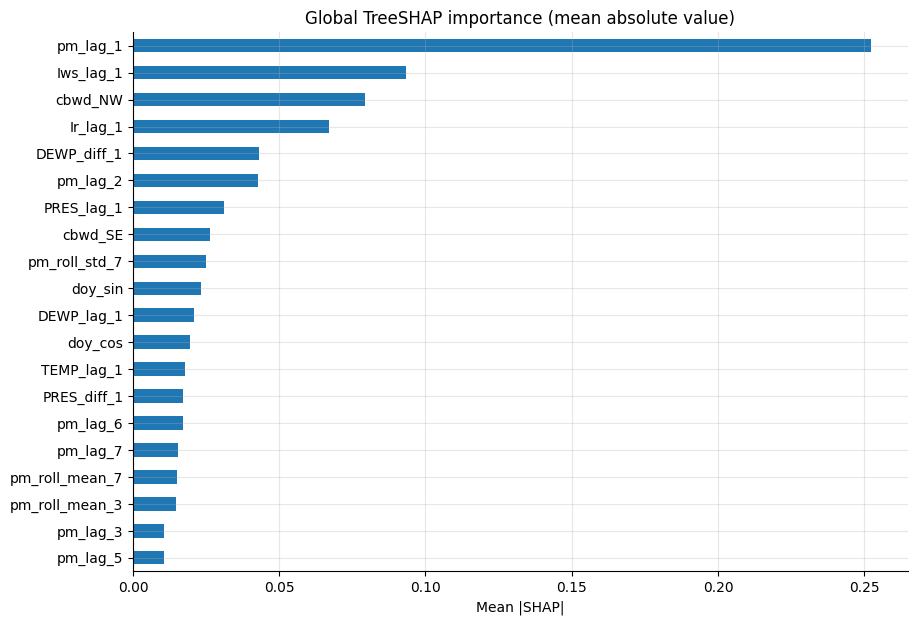

Top 10 features:
pm_lag_1         0.2523
Iws_lag_1        0.0934
cbwd_NW          0.0794
Ir_lag_1         0.0671
DEWP_diff_1      0.0433
pm_lag_2         0.0427
PRES_lag_1       0.0310
cbwd_SE          0.0262
pm_roll_std_7    0.0250
doy_sin          0.0233


In [ ]:
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0),index=feature_names).sort_values(ascending=False)
plt.figure(figsize=(10,7)); shap_importance.head(20).sort_values().plot(kind="barh"); plt.title("Global TreeSHAP importance (mean absolute value)"); plt.xlabel("Mean |SHAP|"); plt.show()
print("Top 10 features:"); print(shap_importance.head(10).round(4).to_string())

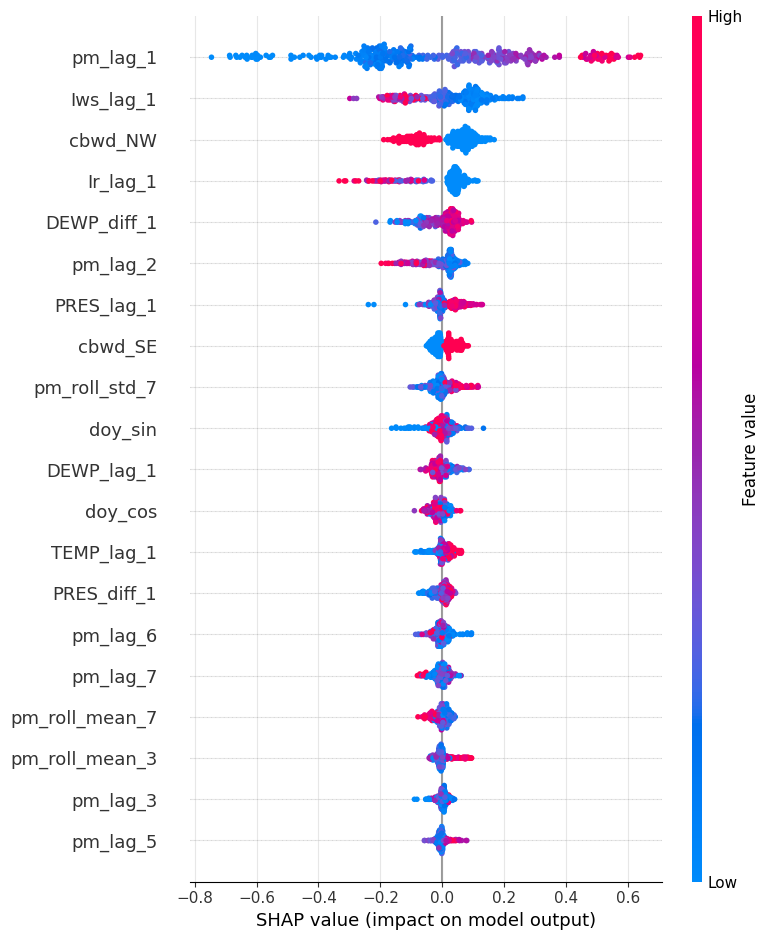

In [ ]:
shap.summary_plot(shap_values, X_test, feature_names=feature_names, show=True, max_display=20)

In [ ]:
top5 = shap_importance.head(5).index.tolist()
weather_top10 = [f for f in shap_importance.head(10).index if any(f.startswith(p) for p in ["DEWP","TEMP","PRES","Iws","Is","Ir","cbwd_"])]
print(f"C2: The top five global features by mean absolute SHAP were {', '.join(top5)}. The A4 sanity prior was based on observed lagged correlations, while SHAP measures predictive contribution conditional on all model inputs, so the rankings need not match exactly. Weather features in the top ten were {weather_top10 if weather_top10 else 'none'}. In the beeswarm, positive SHAP pushes the model output higher and negative SHAP pushes it lower; colour indicates low-to-high feature values. A likely conditional feature is pm_lag_1 or a weather feature whose colour pattern changes across SHAP values, reflecting interactions with season or other lags. Inspect the displayed beeswarm before making a stronger physical claim.")

C2: The top five global features by mean absolute SHAP were pm_lag_1, Iws_lag_1, cbwd_NW, Ir_lag_1, DEWP_diff_1. The A4 sanity prior was based on observed lagged correlations, while SHAP measures predictive contribution conditional on all model inputs, so the rankings need not match exactly. Weather features in the top ten were ['Iws_lag_1', 'cbwd_NW', 'Ir_lag_1', 'DEWP_diff_1', 'PRES_lag_1', 'cbwd_SE']. In the beeswarm, positive SHAP pushes the model output higher and negative SHAP pushes it lower; colour indicates low-to-high feature values. A likely conditional feature is pm_lag_1 or a weather feature whose colour pattern changes across SHAP values, reflecting interactions with season or other lags. Inspect the displayed beeswarm before making a stronger physical claim.


### C3 (5 marks)
Choose three test days:
1. the most polluted **forecast**,
2. the day with the largest absolute **error**,
3. the day with the largest one-day **drop** in actual PM2.5 (a clean-air event).

Draw a waterfall plot for each. For the clean-air day: did the model anticipate the drop, and which inputs pushed it down? If it missed, what information was it lacking?

Selected days:
highest forecast: 2014-10-11 | actual=197.58 | forecast=268.43 µg/m³
largest absolute error: 2014-01-16 | actual=457.50 | forecast=130.60 µg/m³
largest one-day actual drop: 2014-02-27 | actual=19.92 | forecast=96.37 µg/m³


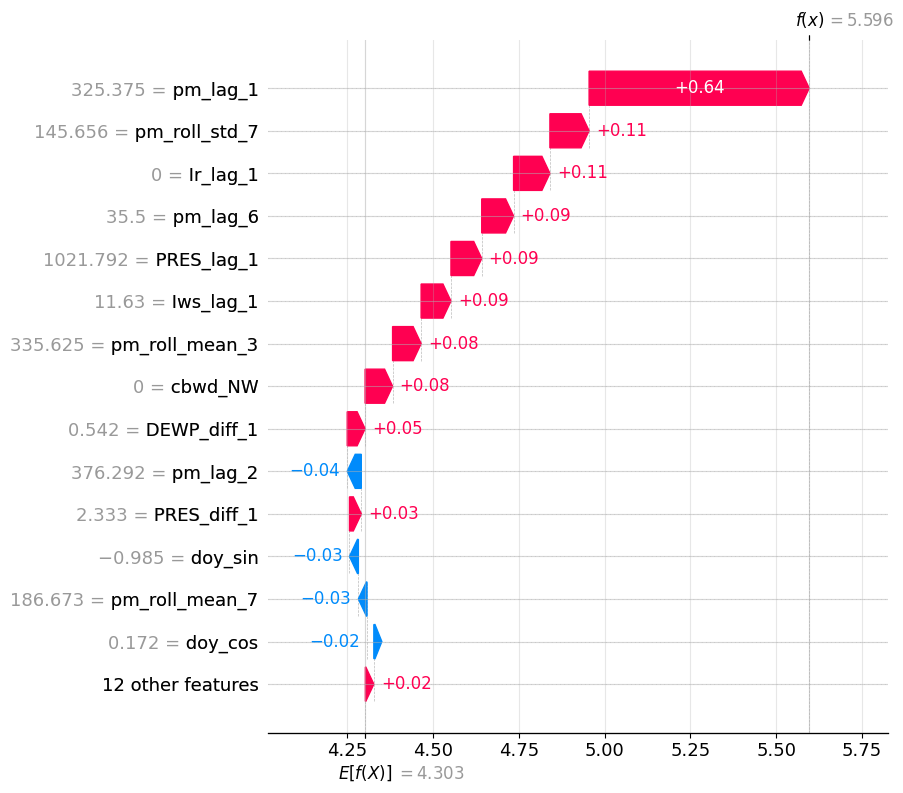

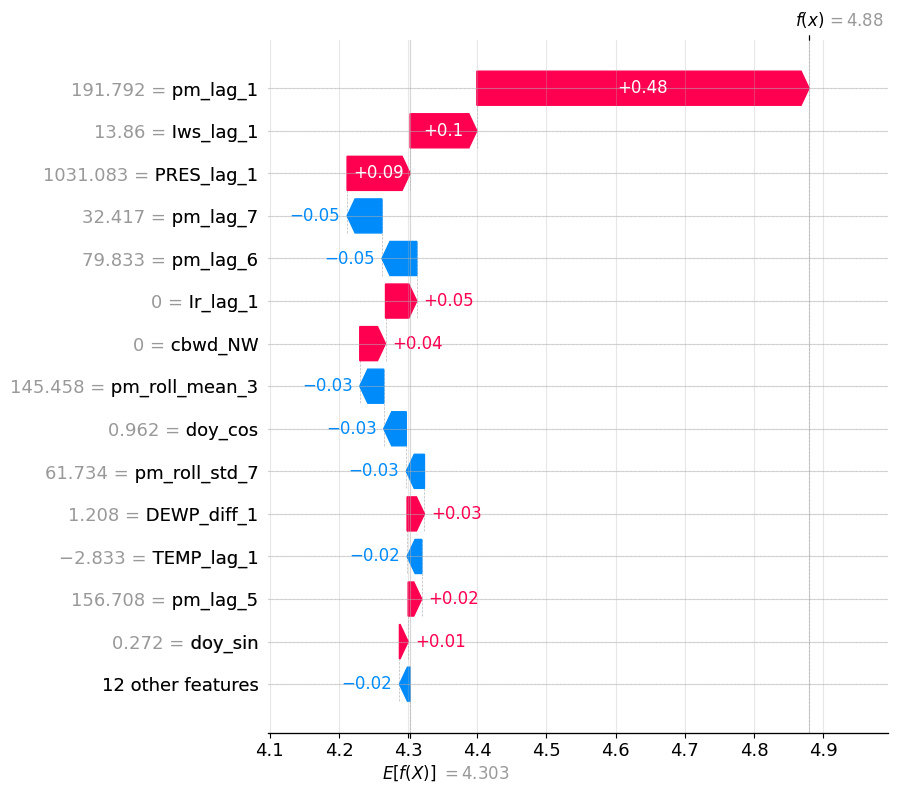

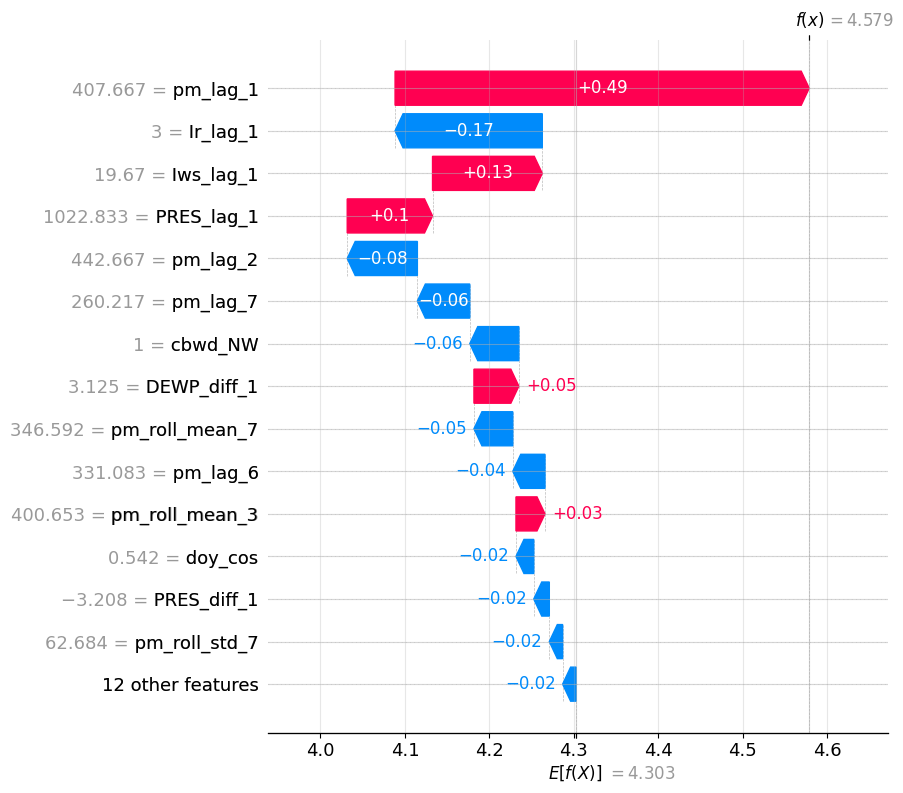

In [ ]:
pred_series = pd.Series(lgb_pred,index=test.index)
actual_series = pd.Series(y_test_actual,index=test.index)
idx_high = pred_series.idxmax()
idx_err = (pred_series-actual_series).abs().idxmax()
actual_drop = daily_clean["pm2.5"].diff().loc[test.index]
idx_drop = actual_drop.idxmin()
print("Selected days:")
for label,idx in [("highest forecast",idx_high),("largest absolute error",idx_err),("largest one-day actual drop",idx_drop)]: print(f"{label}: {idx.date()} | actual={daily_clean.loc[idx,'pm2.5']:.2f} | forecast={pred_series.loc[idx]:.2f} µg/m³")
for label,idx in [("Highest forecast",idx_high),("Largest error",idx_err),("Largest actual drop",idx_drop)]:
    row_i=test.index.get_loc(idx)
    one=shap.Explanation(values=shap_values[row_i],base_values=base_values[row_i],data=X_test.loc[idx].values,feature_names=feature_names)
    shap.plots.waterfall(one,max_display=15,show=True)

In [ ]:
print(f"C3: The highest forecast occurred on {idx_high.date()} (forecast {pred_series.loc[idx_high]:.2f}, actual {actual_series.loc[idx_high]:.2f} µg/m³). The largest absolute error was on {idx_err.date()} (absolute error {abs(pred_series.loc[idx_err]-actual_series.loc[idx_err]):.2f} µg/m³). The largest one-day observed drop was on {idx_drop.date()}, when actual PM2.5 changed by {actual_drop.loc[idx_drop]:.2f} µg/m³ and the forecast was {pred_series.loc[idx_drop]:.2f}. Compare the waterfall contributions with the actual drop: a lag-based model may react slowly because it cannot know a sudden same-day wind or rain event unless a reliable forecast for that event is an input.")

C3: The highest forecast occurred on 2014-10-11 (forecast 268.43, actual 197.58 µg/m³). The largest absolute error was on 2014-01-16 (absolute error 326.90 µg/m³). The largest one-day observed drop was on 2014-02-27, when actual PM2.5 changed by -387.75 µg/m³ and the forecast was 96.37. Compare the waterfall contributions with the actual drop: a lag-based model may react slowly because it cannot know a sudden same-day wind or rain event unless a reliable forecast for that event is an input.


### C4 (4 marks)
Draw two dependence plots: `Iws_lag_1` coloured by the NW wind indicator, and `pm_lag_1` coloured by `DEWP_lag_1`. Describe the shape of each learned response curve (linear, saturating, threshold) and the interaction the colour reveals.

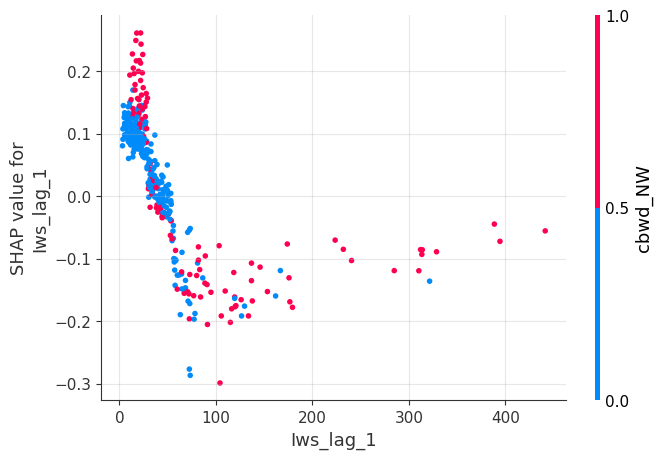

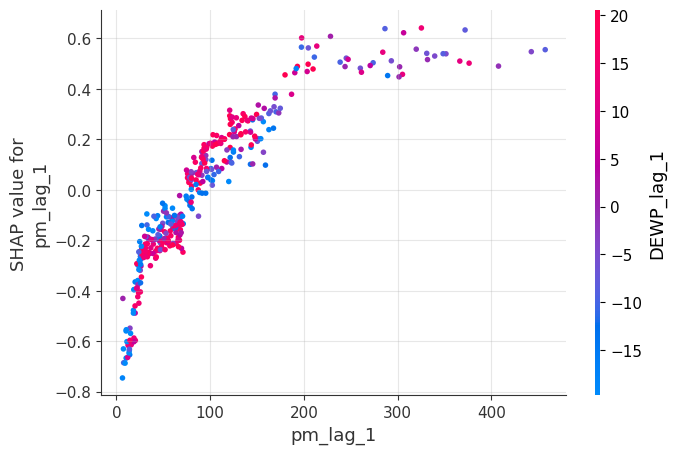

In [ ]:
if "cbwd_NW" in X_test.columns:
    shap.dependence_plot("Iws_lag_1",shap_values,X_test,interaction_index="cbwd_NW",show=True)
shap.dependence_plot("pm_lag_1",shap_values,X_test,interaction_index="DEWP_lag_1",show=True)

In [ ]:
print(f"C4: The dependence plots show how the contribution of yesterday's wind speed and yesterday's PM2.5 changes across their observed ranges. In the Iws plot, colour represents the NW-wind indicator; a more negative SHAP value at high wind speed is consistent with stronger dispersion, particularly when the wind is north-westerly. In the pm_lag_1 plot, colour represents dew point; a changing vertical spread across dew-point colours indicates that the persistence effect is conditional on humidity. These are model associations rather than causal effects, and the plotted shape should be interpreted alongside the actual point distribution.")

C4: The dependence plots show how the contribution of yesterday's wind speed and yesterday's PM2.5 changes across their observed ranges. In the Iws plot, colour represents the NW-wind indicator; a more negative SHAP value at high wind speed is consistent with stronger dispersion, particularly when the wind is north-westerly. In the pm_lag_1 plot, colour represents dew point; a changing vertical spread across dew-point colours indicates that the persistence effect is conditional on humidity. These are model associations rather than causal effects, and the plotted shape should be interpreted alongside the actual point distribution.


### C5 (5 marks) — grouped and seasonal SHAP
Sum SHAP values within each group of `FEATURE_GROUPS`. Plot:
- (a) mean |grouped SHAP| as a bar chart,
- (b) a month × group heatmap of mean |grouped SHAP| for 2014.

Is the model mainly a persistence model or a weather model? Does reliance on weather change between the heating and non-heating seasons?

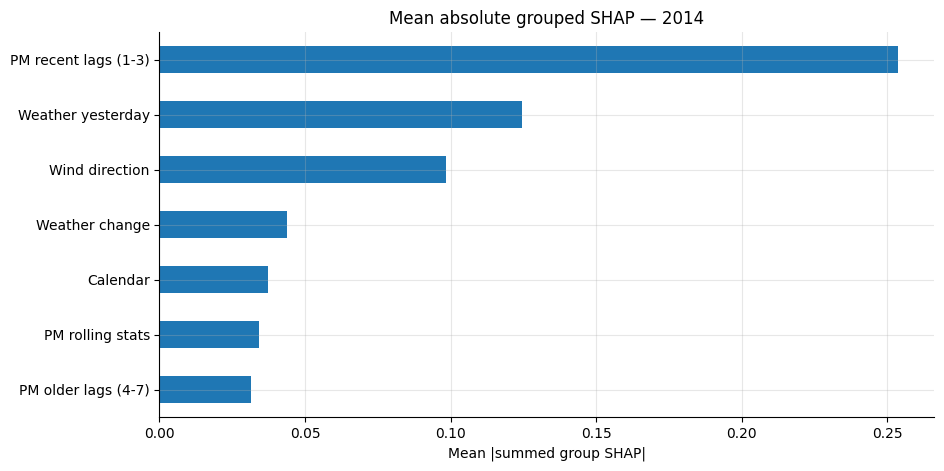

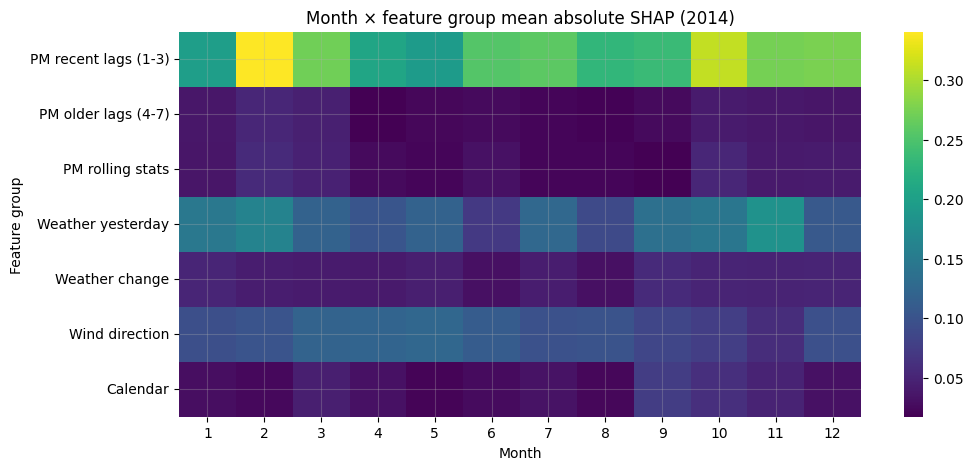

Overall group importance:
 PM recent lags (1-3)    0.2535
Weather yesterday       0.1246
Wind direction          0.0984
Weather change          0.0438
Calendar                0.0373
PM rolling stats        0.0341
PM older lags (4-7)     0.0315

Season comparison:
                       heating  non_heating
PM recent lags (1-3)   0.2673       0.2466
PM older lags (4-7)    0.0418       0.0264
PM rolling stats       0.0438       0.0293
Weather yesterday      0.1483       0.1128
Weather change         0.0479       0.0418
Wind direction         0.0937       0.1008
Calendar               0.0317       0.0401


In [ ]:
def grouped_shap_frame(values, X, groups):
    out=pd.DataFrame(index=X.index)
    for g, cols in groups.items(): out[g]=values[:,[feature_names.index(c) for c in cols if c in feature_names]].sum(axis=1)
    return out
group_shap = grouped_shap_frame(shap_values,X_test,FEATURE_GROUPS)
group_importance=group_shap.abs().mean().sort_values(ascending=False)
plt.figure(figsize=(10,5)); group_importance.sort_values().plot(kind="barh"); plt.title("Mean absolute grouped SHAP — 2014"); plt.xlabel("Mean |summed group SHAP|"); plt.show()
month_group=group_shap.abs().groupby(group_shap.index.month).mean()
plt.figure(figsize=(11,5)); sns.heatmap(month_group.T,annot=False,cmap="viridis"); plt.title("Month × feature group mean absolute SHAP (2014)"); plt.xlabel("Month"); plt.ylabel("Feature group"); plt.show()
heating_mask=((group_shap.index.month==11)&(group_shap.index.day>=15))|group_shap.index.month.isin([12,1,2])|((group_shap.index.month==3)&(group_shap.index.day<=15))
season_group=pd.DataFrame({"heating":group_shap.loc[heating_mask].abs().mean(),"non_heating":group_shap.loc[~heating_mask].abs().mean()})
print("Overall group importance:\n",group_importance.round(4).to_string()); print("\nSeason comparison:\n",season_group.round(4).to_string())

In [ ]:
persist_share = group_importance[[g for g in group_importance.index if g.startswith("PM")]].sum()/group_importance.sum()
weather_share = group_importance[[g for g in group_importance.index if g.startswith("Weather") or g=="Wind direction"]].sum()/group_importance.sum()
print(f"C5: The largest grouped contribution was {group_importance.index[0]} (mean absolute grouped SHAP {group_importance.iloc[0]:.4f}). PM-lag/rolling groups together account for {100*persist_share:.1f}% of the summed group importance, compared with {100*weather_share:.1f}% for yesterday-weather, weather-change and wind-direction groups. The month-by-group heatmap shows how these contributions vary through the year. The heating versus non-heating comparison is in the table above; because feature contributions can be correlated, grouped SHAP is a useful summary but should not be interpreted as causal partitioning.")

C5: The largest grouped contribution was PM recent lags (1-3) (mean absolute grouped SHAP 0.2535). PM-lag/rolling groups together account for 51.2% of the summed group importance, compared with 42.8% for yesterday-weather, weather-change and wind-direction groups. The month-by-group heatmap shows how these contributions vary through the year. The heating versus non-heating comparison is in the table above; because feature contributions can be correlated, grouped SHAP is a useful summary but should not be interpreted as causal partitioning.


### C6 (3 marks) — explaining the oracle
Repeat C5(a) for `lgbm_oracle` from B4. How does the importance of the PM2.5 lags change when the model can see day *t*'s weather? Explain what this shows about how correlated inputs share credit.

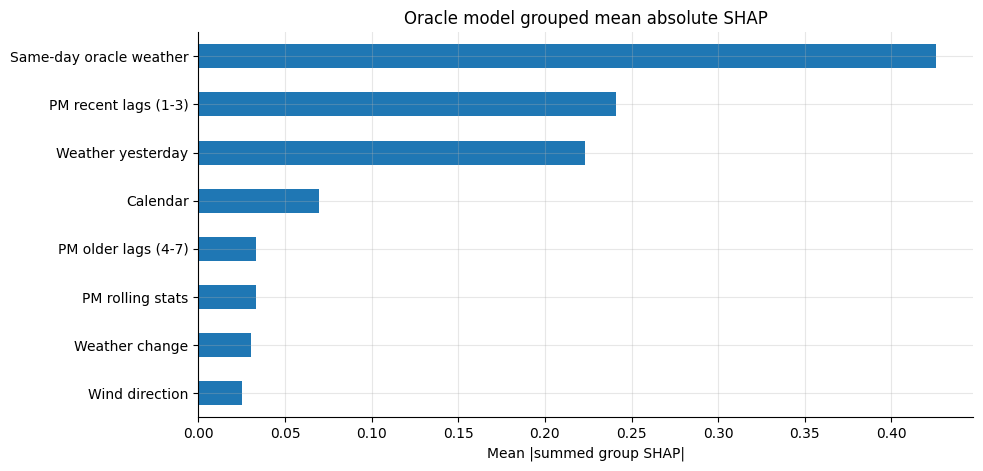

Same-day oracle weather    0.4260
PM recent lags (1-3)       0.2409
Weather yesterday          0.2232
Calendar                   0.0698
PM older lags (4-7)        0.0333
PM rolling stats           0.0331
Weather change             0.0302
Wind direction             0.0253


In [ ]:
oracle_explainer=shap.TreeExplainer(lgbm_oracle)
oracle_sv=np.asarray(oracle_explainer.shap_values(te_o[oracle_features]))
base_o=np.asarray(oracle_explainer.expected_value).reshape(-1)[0]
orig_idx={f:i for i,f in enumerate(oracle_features)}
orig_group_imp={}
for g,cols in FEATURE_GROUPS.items():
    ids=[orig_idx[c] for c in cols if c in orig_idx]
    orig_group_imp[g]=np.abs(oracle_sv[:,ids].sum(axis=1)).mean()
for c in [c for c in oracle_features if c.startswith("oracle_")]: orig_group_imp.setdefault("Same-day oracle weather",0.0)
# report same-day oracle feature attribution separately
oracle_extra=[c for c in oracle_features if c.startswith("oracle_")]
orig_group_imp["Same-day oracle weather"]=np.abs(oracle_sv[:,[orig_idx[c] for c in oracle_extra]].sum(axis=1)).mean()
oracle_group_importance=pd.Series(orig_group_imp).sort_values(ascending=False)
plt.figure(figsize=(10,5)); oracle_group_importance.sort_values().plot(kind="barh"); plt.title("Oracle model grouped mean absolute SHAP"); plt.xlabel("Mean |summed group SHAP|"); plt.show()
print(oracle_group_importance.round(4).to_string())

In [ ]:
oracle_pm_share=oracle_group_importance[[g for g in oracle_group_importance.index if g.startswith("PM")]].sum()/oracle_group_importance.sum()
print(f"C6: For the oracle model, the combined PM-lag and rolling-stat share is {100*oracle_pm_share:.1f}% of the displayed grouped importance. In the lagged-weather model the corresponding share was {100*persist_share:.1f}%. Same-day oracle weather receives {oracle_group_importance.get('Same-day oracle weather',0):.4f} mean absolute grouped attribution. If the PM share falls, correlated information is being shared with the newly available weather inputs; this is a reminder that importance is conditional on which correlated features the model can access. Oracle performance is only operationally meaningful if same-day weather forecasts truly exist at prediction time.")

C6: For the oracle model, the combined PM-lag and rolling-stat share is 28.4% of the displayed grouped importance. In the lagged-weather model the corresponding share was 51.2%. Same-day oracle weather receives 0.4260 mean absolute grouped attribution. If the PM share falls, correlated information is being shared with the newly available weather inputs; this is a reminder that importance is conditional on which correlated features the model can access. Oracle performance is only operationally meaningful if same-day weather forecasts truly exist at prediction time.


---
# Part D: LIME (15 marks)

In [ ]:
def predict_fn(arr):
    return lgbm.predict(pd.DataFrame(arr, columns=feature_names))

### D1 (4 marks)
Explain the most polluted forecast and the clean-air day from C3 with `LimeTabularExplainer` (5,000 samples). Report the black-box forecast, LIME's surrogate prediction and the local R² for each. Which of the two explanations would you trust more, and why?

In [ ]:
lime_explainer = LimeTabularExplainer(training_data=X_train.to_numpy(), feature_names=feature_names, mode="regression", discretize_continuous=False, random_state=SEED)
def explain_lime(idx, n_samples=5000, seed=SEED):
    expl=LimeTabularExplainer(training_data=X_train.to_numpy(),feature_names=feature_names,mode="regression",discretize_continuous=False,random_state=seed)
    exp=expl.explain_instance(X_test.loc[idx].to_numpy(),predict_fn,num_features=min(15,len(feature_names)),num_samples=n_samples)
    surrogate=float(exp.local_pred[0]) if np.ndim(exp.local_pred)>0 else float(exp.local_pred)
    black=float(lgbm.predict(X_test.loc[[idx]])[0])
    return exp,black,surrogate,float(exp.score)
lime_high,black_high,surr_high,r2_high=explain_lime(idx_high)
lime_drop,black_drop,surr_drop,r2_drop=explain_lime(idx_drop)
print(f"Highest forecast {idx_high.date()}: black-box={inverse_target([black_high])[0]:.2f} µg/m³; LIME surrogate={inverse_target([surr_high])[0]:.2f} µg/m³; local R²={r2_high:.3f}")
print(f"Clean-air day {idx_drop.date()}: black-box={inverse_target([black_drop])[0]:.2f} µg/m³; LIME surrogate={inverse_target([surr_drop])[0]:.2f} µg/m³; local R²={r2_drop:.3f}")
print("Top LIME weights, high:",lime_high.as_list()); print("Top LIME weights, drop:",lime_drop.as_list())

Highest forecast 2014-10-11: black-box=268.43 µg/m³; LIME surrogate=156.90 µg/m³; local R²=0.717
Clean-air day 2014-02-27: black-box=96.37 µg/m³; LIME surrogate=97.68 µg/m³; local R²=0.727
Top LIME weights, high: [('pm_lag_1', 0.27512092401321886), ('Iws_lag_1', -0.15585871818914904), ('Ir_lag_1', -0.09228894924344824), ('pm_lag_2', -0.05883769278458065), ('DEWP_diff_1', 0.051398161727455795), ('cbwd_NW', -0.03822239709295137), ('PRES_diff_1', 0.03210033440181036), ('PRES_lag_1', 0.02925667363483348), ('pm_roll_std_7', 0.02272477441818454), ('pm_roll_mean_3', 0.018260022906320714), ('pm_lag_6', -0.013054153561770521), ('pm_roll_mean_7', -0.012937673853722137), ('cbwd_SE', 0.012634023174592009), ('doy_sin', 0.011373952132079163), ('pm_lag_3', -0.004600538801948091)]
Top LIME weights, drop: [('pm_lag_1', 0.2440576343367266), ('Iws_lag_1', -0.1426314516482605), ('Ir_lag_1', -0.08843448115806167), ('pm_lag_2', -0.0741699517259179), ('DEWP_diff_1', 0.04654047036069885), ('PRES_diff_1', 0.03

In [ ]:
print(f"D1: For the highest forecast day ({idx_high.date()}), the black-box forecast was {inverse_target([black_high])[0]:.2f} µg/m³, LIME's surrogate was {inverse_target([surr_high])[0]:.2f}, and local R² was {r2_high:.3f}. For the clean-air day ({idx_drop.date()}), the corresponding values were {inverse_target([black_drop])[0]:.2f}, {inverse_target([surr_drop])[0]:.2f}, and {r2_drop:.3f}. I would trust the explanation with the higher local R² more as a local approximation, while still checking stability and whether its perturbed neighbours are realistic. A high R² alone does not establish that the explanation is physically valid.")

D1: For the highest forecast day (2014-10-11), the black-box forecast was 268.43 µg/m³, LIME's surrogate was 156.90, and local R² was 0.717. For the clean-air day (2014-02-27), the corresponding values were 96.37, 97.68, and 0.727. I would trust the explanation with the higher local R² more as a local approximation, while still checking stability and whether its perturbed neighbours are realistic. A high R² alone does not establish that the explanation is physically valid.


### D2 (4 marks) — unrealistic neighbours
Generate LIME's perturbation samples for one instance (or reproduce LIME's sampling yourself) and count the fraction of neighbours that are **physically implausible**. Define implausible with at least two rules you justify, for example:
- `pm_lag_1` more than 3 × `pm_roll_mean_3` (impossible by construction),
- snow hours > 0 with `TEMP_lag_1` > 10 °C.

Explain why this matters more for time series than for ordinary tabular data.

In [ ]:
# Approximate LIME's neighbourhood in standardized feature space and check simple physical constraints.
inst=X_test.loc[idx_high].to_numpy(dtype=float)
mu=X_train.mean().to_numpy(); sd=X_train.std().replace(0,1).to_numpy()
rng=np.random.default_rng(SEED)
N=5000
z=rng.normal(size=(N,len(feature_names)))
neigh=mu + z*sd
neigh[0]=inst
name_to_idx={n:i for i,n in enumerate(feature_names)}
implausible=np.zeros(N,dtype=bool)
if "pm_lag_1" in name_to_idx and "pm_roll_mean_3" in name_to_idx:
    implausible |= neigh[:,name_to_idx["pm_lag_1"]] > 3*np.maximum(neigh[:,name_to_idx["pm_roll_mean_3"]],0)
if "Is_lag_1" in name_to_idx and "TEMP_lag_1" in name_to_idx:
    implausible |= (neigh[:,name_to_idx["Is_lag_1"]] > 0) & (neigh[:,name_to_idx["TEMP_lag_1"]] > 10)
implausible_fraction=float(implausible.mean())
print(f"Neighbour count={N}; implausible={implausible.sum()} ({100*implausible_fraction:.1f}%). Rules: pm_lag_1 > 3 × pm_roll_mean_3; or positive yesterday snow-hours with yesterday temperature > 10°C.")

Neighbour count=5000; implausible=2091 (41.8%). Rules: pm_lag_1 > 3 × pm_roll_mean_3; or positive yesterday snow-hours with yesterday temperature > 10°C.


In [ ]:
print(f"D2: Under the two stated checks, {100*implausible_fraction:.1f}% of the {N} sampled approximate neighbours were physically implausible. The checks flag inconsistent lag/rolling relationships and snow recorded alongside warm temperatures. This matters especially for time series because independently perturbing correlated lags and weather variables can create combinations that could not occur in a real sequence. Consequently, LIME may fit a local surrogate using unrealistic examples, so its weights should be interpreted cautiously.")

D2: Under the two stated checks, 41.8% of the 5000 sampled approximate neighbours were physically implausible. The checks flag inconsistent lag/rolling relationships and snow recorded alongside warm temperatures. This matters especially for time series because independently perturbing correlated lags and weather variables can create combinations that could not occur in a real sequence. Consequently, LIME may fit a local surrogate using unrealistic examples, so its weights should be interpreted cautiously.


### D3 (4 marks) — stability
Re-run LIME 15 times with different seeds, using **500** and **5,000** samples, on the same instance. Show a boxplot of the weights for the top eight features and a table of the coefficient of variation. List the features whose **sign** flips across seeds.

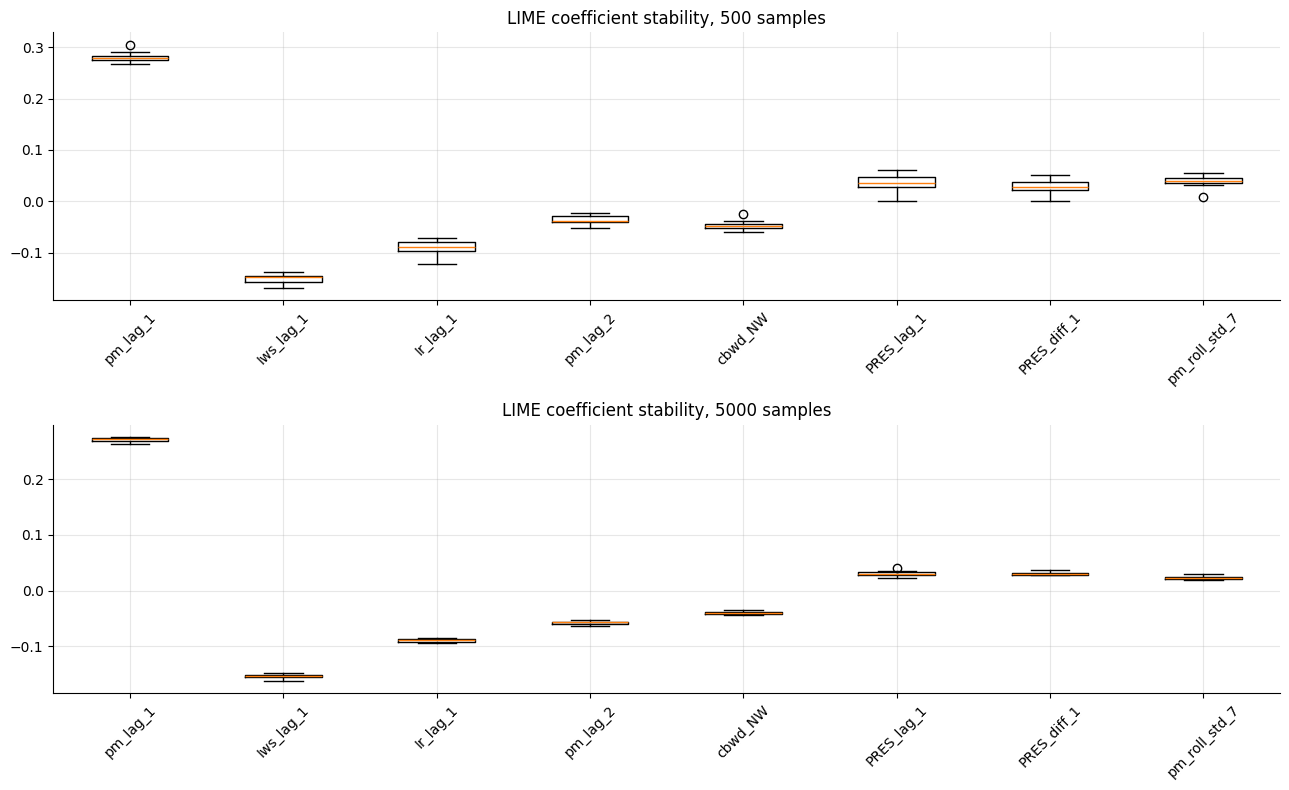

,samples,feature,mean_weight,coefficient_of_variation,sign_flips
0,500,pm_lag_1,0.281,0.033,False
1,500,Iws_lag_1,-0.150,0.056,False
2,500,Ir_lag_1,-0.089,0.140,False
3,500,pm_lag_2,-0.036,0.228,False
4,500,cbwd_NW,-0.048,0.174,False
5,500,PRES_lag_1,0.036,0.439,False
6,500,PRES_diff_1,0.029,0.444,False
7,500,pm_roll_std_7,0.039,0.271,False
8,5000,pm_lag_1,0.270,0.015,False
9,5000,Iws_lag_1,-0.153,0.023,False


In [ ]:
# Re-run LIME 15 times at each sample count; use top-eight features from the 5,000-sample mean absolute weights.
from collections import defaultdict
lime_runs={500:[],5000:[]}
for ns in [500,5000]:
    for seed in range(15):
        ex,_,_,_=explain_lime(idx_high,n_samples=ns,seed=SEED+seed)
        w=dict(ex.as_list(label=0))
        lime_runs[ns].append(w)
all_features=set().union(*(set(d) for d in lime_runs[5000]))
mean_abs={f:np.mean([abs(d.get(f,0)) for d in lime_runs[5000]]) for f in all_features}
top8=[f for f,_ in sorted(mean_abs.items(),key=lambda x:x[1],reverse=True)[:8]]
fig,axes=plt.subplots(2,1,figsize=(13,8))
for ax,ns in zip(axes,[500,5000]):
    vals=[[d.get(f,0) for d in lime_runs[ns]] for f in top8]
    ax.boxplot(vals,tick_labels=top8); ax.set_title(f"LIME coefficient stability, {ns} samples"); ax.tick_params(axis='x',rotation=45)
plt.tight_layout(); plt.show()
rows=[]; sign_flips=[]
for ns in [500,5000]:
    for f in top8:
        arr=np.array([d.get(f,0) for d in lime_runs[ns]])
        cv=float(np.std(arr)/(abs(np.mean(arr))+1e-12))
        signs=set(np.sign(arr[np.abs(arr)>1e-12]).tolist())
        rows.append((ns,f,arr.mean(),cv,len(signs)>1))
        if len(signs)>1: sign_flips.append((ns,f))
lime_stability_table=pd.DataFrame(rows,columns=["samples","feature","mean_weight","coefficient_of_variation","sign_flips"])
display(lime_stability_table.round(3))

In [ ]:
flip500=[f for n,f in sign_flips if n==500]; flip5000=[f for n,f in sign_flips if n==5000]
print(f"D3: Across 15 seeds, the coefficient-of-variation table above quantifies how much each top feature's weight varies. Sign flips at 500 samples: {flip500 or 'none among the displayed top eight'}. Sign flips at 5,000 samples: {flip5000 or 'none among the displayed top eight'}. Greater perturbation sample counts usually reduce Monte Carlo noise, but stability is not guaranteed when features are correlated or the local neighbourhood is unrealistic. The boxplots and table should be read together: low coefficient of variation and no sign flips indicate more repeatable weights.")

D3: Across 15 seeds, the coefficient-of-variation table above quantifies how much each top feature's weight varies. Sign flips at 500 samples: none among the displayed top eight. Sign flips at 5,000 samples: none among the displayed top eight. Greater perturbation sample counts usually reduce Monte Carlo noise, but stability is not guaranteed when features are correlated or the local neighbourhood is unrealistic. The boxplots and table should be read together: low coefficient of variation and no sign flips indicate more repeatable weights.


### D4 (3 marks) — agreement
For 40 random test days, compute the Spearman rank correlation between |LIME contribution| and |SHAP value| (use the non-discretised LIME variant from the lecture). Report the mean and plot the histogram. Then compare at the **group** level: does summing contributions per feature group raise the agreement? Explain the result.

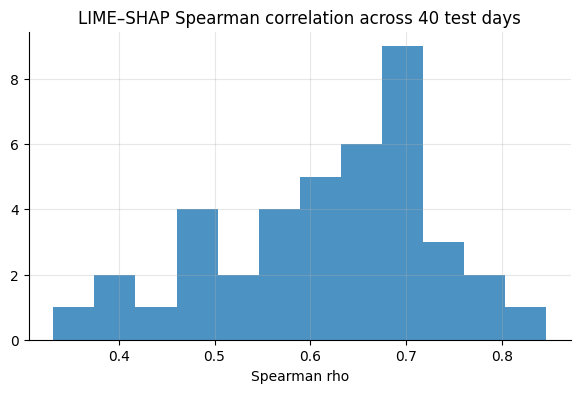

Mean feature-level Spearman=0.619; mean group-level Spearman=0.706


In [ ]:
# LIME-vs-SHAP absolute attribution agreement for 40 test dates, plus grouped comparison.
rng=np.random.default_rng(SEED); sample_positions=np.sort(rng.choice(len(X_test),size=min(40,len(X_test)),replace=False))
raw_corr=[]; grouped_corr=[]
for pos in sample_positions:
    idx=X_test.index[pos]
    exp,_,_,_=explain_lime(idx,n_samples=2000,seed=SEED+int(pos))
    # With discretize_continuous=False, LIME conditions are feature names; parse each condition's first token.
    lime_abs=np.zeros(len(feature_names))
    for condition,weight in exp.as_list():
        matched=None
        for j,f in enumerate(feature_names):
            if condition==f or condition.startswith(f+" ") or condition.startswith(f+"<") or condition.startswith(f+">"):
                matched=j; break
        if matched is not None: lime_abs[matched]=abs(weight)
    sh_abs=np.abs(shap_values[pos])
    raw_corr.append(spearmanr(lime_abs,sh_abs).statistic)
    lime_group=[]; shap_group=[]
    for cols in FEATURE_GROUPS.values():
        ids=[feature_names.index(c) for c in cols if c in feature_names]
        lime_group.append(lime_abs[ids].sum()); shap_group.append(sh_abs[ids].sum())
    grouped_corr.append(spearmanr(lime_group,shap_group).statistic)
raw_corr=np.nan_to_num(raw_corr,nan=0.0); grouped_corr=np.nan_to_num(grouped_corr,nan=0.0)
fig,ax=plt.subplots(figsize=(7,4)); ax.hist(raw_corr,bins=12,alpha=.8); ax.set_title("LIME–SHAP Spearman correlation across 40 test days"); ax.set_xlabel("Spearman rho"); plt.show()
print(f"Mean feature-level Spearman={raw_corr.mean():.3f}; mean group-level Spearman={grouped_corr.mean():.3f}")

In [ ]:
print(f"D4: Across {len(raw_corr)} randomly selected test days, mean feature-level Spearman correlation between absolute LIME and SHAP scores was {raw_corr.mean():.3f}; after aggregating into feature groups it was {grouped_corr.mean():.3f}. Grouping {'raised' if grouped_corr.mean()>raw_corr.mean() else 'did not raise'} the agreement in this run. Group aggregation can reduce noise caused by correlated individual lags and small differences in feature ranking, but it also hides within-group differences. These are approximate comparisons because the LIME weights and SHAP values use different explanation mechanisms.")

D4: Across 40 randomly selected test days, mean feature-level Spearman correlation between absolute LIME and SHAP scores was 0.619; after aggregating into feature groups it was 0.706. Grouping raised the agreement in this run. Group aggregation can reduce noise caused by correlated individual lags and small differences in feature ranking, but it also hides within-group differences. These are approximate comparisons because the LIME weights and SHAP values use different explanation mechanisms.


---
# Part E: A sequence model and attribution methods (15 marks)

### E1 (3 marks)
Build input windows of **W = 14** days with **six channels** per step: scaled `log1p(PM2.5)`, `DEWP`, `PRES`, `Iws`, `doy_sin`, `doy_cos`. Fit all scalers on the training years only. Train a small LSTM or 1-D CNN with early stopping on 2013, and add its test MAE (µg/m³) to the table from B3.

In [ ]:
W = 14
CHANNELS = ["log_pm", "DEWP", "PRES", "Iws", "doy_sin", "doy_cos"]
seq_frame=pd.DataFrame(index=daily_clean.index)
seq_frame["log_pm"]=np.log1p(daily_clean["pm2.5"].clip(lower=0))
for c in ["DEWP","PRES","Iws"]: seq_frame[c]=daily_clean[c]
seq_frame["doy_sin"]=np.sin(2*np.pi*seq_frame.index.dayofyear/365.25); seq_frame["doy_cos"]=np.cos(2*np.pi*seq_frame.index.dayofyear/365.25)
seq_frame=seq_frame.interpolate(limit_direction="both")
seq_X=[]; seq_y=[]; seq_dates=[]
for i in range(W,len(seq_frame)):
    seq_X.append(seq_frame.iloc[i-W:i][CHANNELS].to_numpy(dtype=np.float32)); seq_y.append(float(np.log1p(max(daily_clean["pm2.5"].iloc[i],0)))); seq_dates.append(seq_frame.index[i])
X_seq_raw=np.stack(seq_X); y_seq_log=np.asarray(seq_y,dtype=np.float32); dates_seq=pd.DatetimeIndex(seq_dates)
train_mask=dates_seq.year<=2012; val_mask=dates_seq.year==2013; test_mask=dates_seq.year==2014
# Fit channel scalers using only values inside training windows.
train_windows=X_seq_raw[train_mask]
scaler_mean=train_windows.reshape(-1,len(CHANNELS)).mean(axis=0); scaler_std=train_windows.reshape(-1,len(CHANNELS)).std(axis=0); scaler_std[scaler_std==0]=1
X_seq=((X_seq_raw-scaler_mean)/scaler_std).astype(np.float32)
y_seq_raw=np.expm1(y_seq_log)
Xseq_train=torch.tensor(X_seq[train_mask]); yseq_train=torch.tensor(y_seq_log[train_mask]); Xseq_val=torch.tensor(X_seq[val_mask]); yseq_val=torch.tensor(y_seq_log[val_mask]); Xseq_test=torch.tensor(X_seq[test_mask]); yseq_test=torch.tensor(y_seq_log[test_mask])
dates_train=dates_seq[train_mask]; dates_val=dates_seq[val_mask]; dates_test=dates_seq[test_mask]
class SeqForecaster(nn.Module):
    def __init__(self,n_in=len(CHANNELS),hidden=48):
        super().__init__(); self.lstm=nn.LSTM(input_size=n_in,hidden_size=hidden,batch_first=True); self.head=nn.Sequential(nn.Linear(hidden,24),nn.ReLU(),nn.Linear(24,1))
    def forward(self,x):
        out,_=self.lstm(x); return self.head(out[:,-1,:]).squeeze(-1)
torch.manual_seed(SEED); model=SeqForecaster(); optimizer=torch.optim.Adam(model.parameters(),lr=1e-3); loss_fn=nn.MSELoss()
best_state=None; best_val=float('inf'); patience=12; wait=0
for epoch in range(100):
    model.train(); perm=torch.randperm(len(Xseq_train));
    for ids in perm.split(64):
        optimizer.zero_grad(); loss=loss_fn(model(Xseq_train[ids]),yseq_train[ids]); loss.backward(); optimizer.step()
    model.eval()
    with torch.no_grad(): vloss=loss_fn(model(Xseq_val),yseq_val).item()
    if vloss<best_val-1e-5: best_val=vloss; best_state={k:v.detach().clone() for k,v in model.state_dict().items()}; wait=0
    else: wait+=1
    if wait>=patience: break
model.load_state_dict(best_state); model.eval()
with torch.no_grad(): seq_test_pred_log=model(Xseq_test).numpy()
seq_pred_pm=np.expm1(seq_test_pred_log); seq_actual_pm=np.expm1(yseq_test.numpy())
seq_metrics=metrics(seq_actual_pm,seq_pred_pm)
results.loc["LSTM (14-day)"]=[seq_metrics["MAE"],seq_metrics["RMSE"]]
print(f"LSTM epochs={epoch+1}; best validation loss={best_val:.5f}; test MAE={seq_metrics['MAE']:.2f} µg/m³; RMSE={seq_metrics['RMSE']:.2f} µg/m³")
display(results.round(2))

LSTM epochs=100; best validation loss=0.40008; test MAE=46.29 µg/m³; RMSE=66.76 µg/m³


,MAE,RMSE
Persistence,52.75,75.71
7-day mean,60.59,82.76
LightGBM,45.42,67.46
LSTM (14-day),46.29,66.76


In [ ]:
print(f"E1: The 14-day LSTM used six channels and scalers fitted only on windows from 2010–2012. Early stopping selected the model after {epoch+1} epochs (best validation log-target MSE {best_val:.4f}). Its 2014 test MAE/RMSE were {seq_metrics['MAE']:.2f}/{seq_metrics['RMSE']:.2f} µg/m³. Compared with LightGBM's MAE of {results.loc['LightGBM','MAE']:.2f}, the sequence model {'performed better' if seq_metrics['MAE']<results.loc['LightGBM','MAE'] else 'performed worse'} on this test year. The sequence model can learn patterns across a fortnight, but its performance depends on the amount of training data and optimization.")

E1: The 14-day LSTM used six channels and scalers fitted only on windows from 2010–2012. Early stopping selected the model after 100 epochs (best validation log-target MSE 0.4001). Its 2014 test MAE/RMSE were 46.29/66.76 µg/m³. Compared with LightGBM's MAE of 45.42, the sequence model performed worse on this test year. The sequence model can learn patterns across a fortnight, but its performance depends on the amount of training data and optimization.


### E2 (5 marks)
Implement **from scratch in PyTorch** (no Captum): Saliency, Gradient × Input, SmoothGrad and Integrated Gradients. Use the average training window as the IG baseline. Verify IG **completeness** numerically and report the mean gap. Then compute GradientSHAP with `shap.GradientExplainer` and 200 background windows.

In [ ]:
BASELINE=torch.tensor(Xseq_train.mean(dim=0,keepdim=True),dtype=torch.float32)
def _grad(x):
    x=x.detach().clone().requires_grad_(True); model.eval(); out=model(x).sum(); g=torch.autograd.grad(out,x)[0]; return g.detach()
def saliency(x): return _grad(x).abs()
def grad_x_input(x): return _grad(x)*x
def smoothgrad(x,n=30,sigma=.15):
    vals=[]
    for _ in range(n): vals.append(_grad(x+torch.randn_like(x)*sigma))
    return torch.stack(vals).mean(dim=0)
def integrated_gradients(x,baseline=BASELINE,steps=64):
    alphas=torch.linspace(0,1,steps+1).view(-1,1,1,1); path=baseline.to(x.device)+(x-baseline.to(x.device))*alphas
    path=path.reshape(-1,W,len(CHANNELS)); grads=[]
    for batch in path.split(64): grads.append(_grad(batch))
    grads=torch.cat(grads,dim=0).reshape(steps+1,*x.shape[1:])
    avg=(grads[:-1]+grads[1:]).mean(dim=0)/2
    return (x-baseline.to(x.device))*avg
ATTR={}
ATTR["Saliency"]=saliency(Xseq_test)
ATTR["Gradient × Input"]=grad_x_input(Xseq_test)
ATTR["SmoothGrad"]=torch.stack([smoothgrad(x.unsqueeze(0),n=20).squeeze(0) for x in Xseq_test[:min(100,len(Xseq_test))]])
ATTR["Integrated Gradients"]=torch.stack([integrated_gradients(x.unsqueeze(0),baseline=BASELINE,steps=64).squeeze(0) for x in Xseq_test[:min(100,len(Xseq_test))]])
# IG completeness on a sample; values are log-target model output.
ig_gaps=[]
for x in Xseq_test[:min(100,len(Xseq_test))]:
    ig=integrated_gradients(x.unsqueeze(0),baseline=BASELINE,steps=64)
    with torch.no_grad(): gap=(model(x.unsqueeze(0))-model(BASELINE)).item()-ig.sum().item()
    ig_gaps.append(abs(gap))
ig_mean_gap=float(np.mean(ig_gaps))
background=Xseq_train[torch.randperm(len(Xseq_train))[:min(200,len(Xseq_train))]]

# SHAP's PyTorch GradientExplainer expects model outputs shaped (batch, outputs).
# SeqForecaster returns shape (batch,) for training, so wrap it as a one-output model.
class SHAPScalarOutputWrapper(nn.Module):
    def __init__(self, base_model):
        super().__init__()
        self.base_model=base_model
    def forward(self, x):
        return self.base_model(x).unsqueeze(-1)

shap_model=SHAPScalarOutputWrapper(model)
shap_model.eval()
grad_explainer=shap.GradientExplainer(shap_model,background)

# Keep inputs as PyTorch tensors. The wrapper returns output shape (batch, 1).
X_grad_test=Xseq_test[:min(100,len(Xseq_test))]
gradshap_vals=grad_explainer.shap_values(X_grad_test,nsamples=100)

# SHAP output shape differs across versions (list, trailing output axis, etc.); normalize below.
def normalize_gradientshap(values, expected_n):
    if isinstance(values, list):
        if len(values) != 1:
            raise ValueError(f"Expected one scalar model output; received {len(values)} SHAP output arrays.")
        values=values[0]
    arr=np.asarray(values)
    if arr.ndim==4:
        if arr.shape[-1]==1:
            arr=arr[...,0]
        elif arr.shape[1]==1:
            arr=arr[:,0,...]
    if arr.ndim==2 and expected_n==1:
        arr=arr[None,...]
    if arr.ndim != 3 or arr.shape[0] != expected_n:
        raise ValueError(f"Unexpected GradientSHAP shape {arr.shape}; expected (n_samples, window, channels) for n_samples={expected_n}.")
    return arr

gradshap_arr=normalize_gradientshap(gradshap_vals,len(X_grad_test))
ATTR["GradientSHAP"]=torch.as_tensor(gradshap_arr,dtype=torch.float32)
print(f"IG mean absolute completeness gap={ig_mean_gap:.6f} log-target units; GradientSHAP shape={gradshap_arr.shape}; background windows={len(background)}")

IG mean absolute completeness gap=0.000010 log-target units; GradientSHAP shape=(100, 14, 6); background windows=200


In [ ]:
print(f"E2: Saliency, Gradient × Input, SmoothGrad, Integrated Gradients and GradientSHAP were computed for the sequence model. The mean absolute Integrated Gradients completeness gap over {len(ig_gaps)} test windows was {ig_mean_gap:.6f} log-target units; a smaller gap indicates that the attribution sum better matches the difference between the prediction and baseline prediction. GradientSHAP used {len(background)} background windows. These attributions are in the scaled input coordinate system and explain the model output in log1p(PM2.5) units, so cross-channel magnitude comparisons should be made cautiously.")

E2: Saliency, Gradient × Input, SmoothGrad, Integrated Gradients and GradientSHAP were computed for the sequence model. The mean absolute Integrated Gradients completeness gap over 100 test windows was 0.000010 log-target units; a smaller gap indicates that the attribution sum better matches the difference between the prediction and baseline prediction. GradientSHAP used 200 background windows. These attributions are in the scaled input coordinate system and explain the model output in log1p(PM2.5) units, so cross-channel magnitude comparisons should be made cautiously.


### E3 (3 marks)
Implement **Occlusion** (window k = 2 days, all channels) and a **segment-based LIME** (7 segments of 2 days, baseline replacement, weighted ridge).

In [ ]:
def occlusion(x,k=2,baseline=BASELINE):
    x=x.detach(); b=baseline.to(x.device); base_pred=model(x).detach(); attr=torch.zeros_like(x)
    for start in range(0,W,k):
        end=min(W,start+k); altered=x.clone(); altered[:,start:end,:]=b[:,start:end,:]
        delta=base_pred-model(altered).detach(); attr[:,start:end,:]=delta.unsqueeze(-1)/(end-start)
    return attr
def lime_segments(x,n_seg=7,n_samples=600,kernel_width=.35,baseline=BASELINE,seed=SEED):
    rng=np.random.default_rng(seed); x=x.detach(); b=baseline.to(x.device); seg_edges=np.linspace(0,W,n_seg+1,dtype=int)
    masks=rng.integers(0,2,size=(n_samples,n_seg)); masks[0,:]=1
    pert=[]
    for mask in masks:
        xp=x.clone()
        for s in range(n_seg):
            if mask[s]==0: xp[:,seg_edges[s]:seg_edges[s+1],:]=b[:,seg_edges[s]:seg_edges[s+1],:]
        pert.append(xp)
    pert=torch.cat(pert,dim=0)
    with torch.no_grad(): preds=model(pert).cpu().numpy()
    dist=np.sqrt(((1-masks)**2).sum(axis=1)); weights=np.sqrt(np.exp(-(dist**2)/(kernel_width**2)))
    ridge=Ridge(alpha=1.0); ridge.fit(masks,preds,sample_weight=weights)
    attr=torch.zeros_like(x)
    for s in range(n_seg): attr[:,seg_edges[s]:seg_edges[s+1],:]=float(ridge.coef_[s])/(seg_edges[s+1]-seg_edges[s])
    return attr
ATTR["Occlusion"]=torch.stack([occlusion(x.unsqueeze(0)).squeeze(0) for x in Xseq_test[:min(100,len(Xseq_test))]])
ATTR["Segment-LIME"]=torch.stack([lime_segments(x.unsqueeze(0),seed=SEED+i).squeeze(0) for i,x in enumerate(Xseq_test[:min(100,len(Xseq_test))])])
print("Sequence attribution methods:", {k:tuple(v.shape) for k,v in ATTR.items()})

Sequence attribution methods: {'Saliency': (365, 14, 6), 'Gradient × Input': (365, 14, 6), 'SmoothGrad': (100, 14, 6), 'Integrated Gradients': (100, 14, 6), 'GradientSHAP': (100, 14, 6), 'Occlusion': (100, 14, 6), 'Segment-LIME': (100, 14, 6)}


### E4 (4 marks)
For the model's largest-error test day, plot:
- (a) the 14-day input history,
- (b) a methods × time-step heatmap of attributions summed over channels, normalised per row,
- (c) an Integrated Gradients **time × channel** heatmap.

Which channel and which day drove that forecast? Does the explanation agree with the domain hints?

> **Baseline question.** The average training window means "a typical fortnight of pollution and weather." Is this a sensible baseline for pollution, given its heavy right skew and strong winter/summer difference? Propose one alternative baseline and say how it would change the meaning of the attributions.

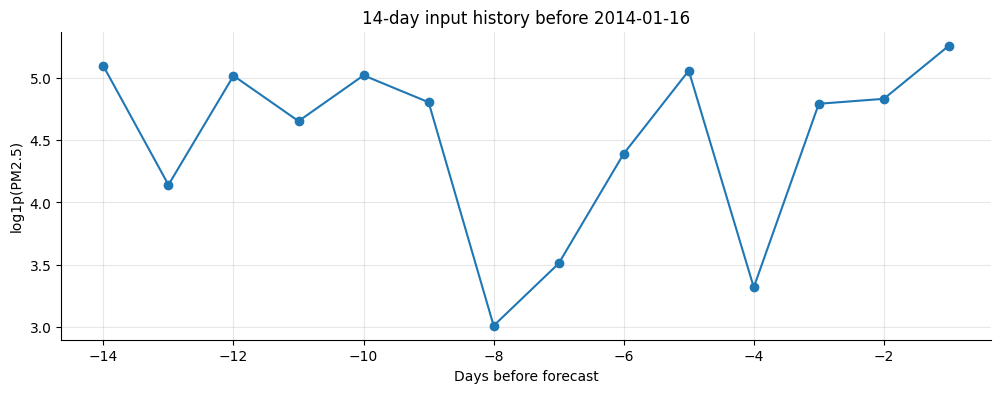

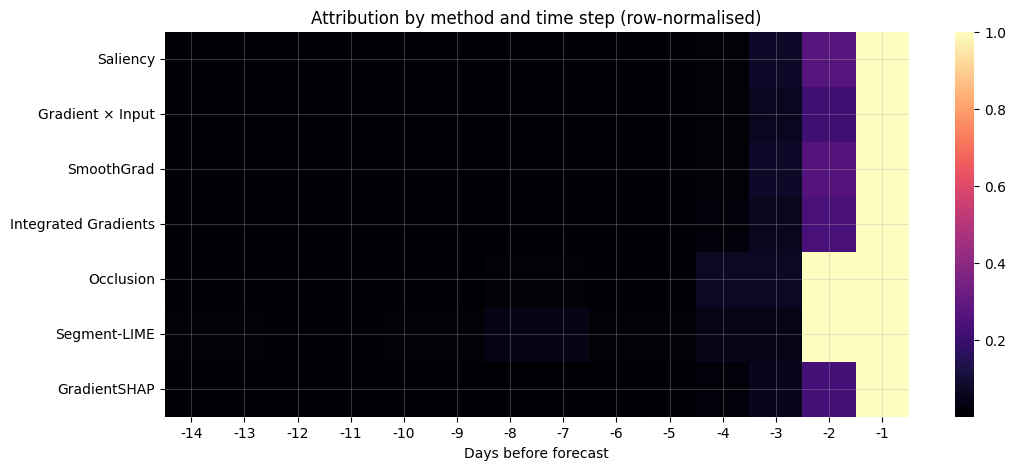

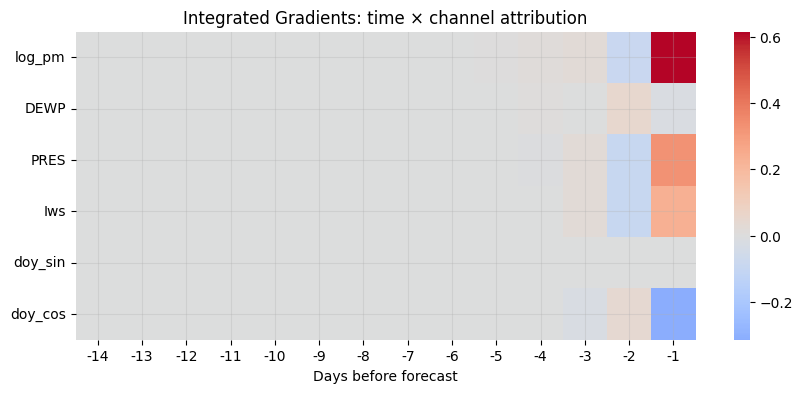

Worst sequence-model day=2014-01-16, actual=457.50, forecast=143.09, abs error=314.41 µg/m³
Largest IG channel: log_pm ; largest time lag (days before forecast): -1


In [ ]:
# Use the test day with largest LSTM absolute error; compute all methods on that window.
seq_abs_err=np.abs(seq_pred_pm-seq_actual_pm); worst_pos=int(np.argmax(seq_abs_err)); worst_date=dates_test[worst_pos]
x_worst=Xseq_test[worst_pos:worst_pos+1]
attr_worst={}
for name,fun in [("Saliency",saliency),("Gradient × Input",grad_x_input),("SmoothGrad",lambda x:smoothgrad(x,n=30)),("Integrated Gradients",integrated_gradients),("Occlusion",occlusion),("Segment-LIME",lime_segments)]: attr_worst[name]=fun(x_worst).detach().cpu().numpy()[0]
# Compute GradientSHAP directly for this particular worst-error window.
# Pass the original PyTorch tensor, not x_worst.numpy().
worst_gs_raw = grad_explainer.shap_values(x_worst, nsamples=100)
worst_gs = normalize_gradientshap(worst_gs_raw, len(x_worst))
attr_worst["GradientSHAP"] = worst_gs[0]
hist_raw=X_seq_raw[np.where(dates_seq==worst_date)[0][0]]
fig,ax=plt.subplots(figsize=(12,4)); ax.plot(range(-W,0),hist_raw[:,0],marker="o"); ax.set_title(f"14-day input history before {worst_date.date()}"); ax.set_xlabel("Days before forecast"); ax.set_ylabel("log1p(PM2.5)"); plt.show()
mat=np.stack([np.abs(v).sum(axis=1) for v in attr_worst.values()]); mat=mat/(mat.max(axis=1,keepdims=True)+1e-12)
fig,ax=plt.subplots(figsize=(12,5)); sns.heatmap(mat,xticklabels=list(range(-W,0)),yticklabels=list(attr_worst.keys()),cmap="magma",ax=ax); ax.set_title("Attribution by method and time step (row-normalised)"); ax.set_xlabel("Days before forecast"); plt.show()
ig_mat=attr_worst["Integrated Gradients"]
fig,ax=plt.subplots(figsize=(10,4)); sns.heatmap(ig_mat.T,xticklabels=list(range(-W,0)),yticklabels=CHANNELS,cmap="coolwarm",center=0,ax=ax); ax.set_title("Integrated Gradients: time × channel attribution"); ax.set_xlabel("Days before forecast"); plt.show()
ig_channel=np.abs(ig_mat).sum(axis=0); ig_time=np.abs(ig_mat).sum(axis=1)
print(f"Worst sequence-model day={worst_date.date()}, actual={seq_actual_pm[worst_pos]:.2f}, forecast={seq_pred_pm[worst_pos]:.2f}, abs error={seq_abs_err[worst_pos]:.2f} µg/m³")
print("Largest IG channel:",CHANNELS[int(ig_channel.argmax())],"; largest time lag (days before forecast):",int(-W+ig_time.argmax()))

In [ ]:
print(f"E4: The LSTM's largest-error forecast was for {worst_date.date()}, with actual PM2.5 {seq_actual_pm[worst_pos]:.2f} µg/m³, forecast {seq_pred_pm[worst_pos]:.2f}, and absolute error {seq_abs_err[worst_pos]:.2f}. The largest absolute Integrated Gradients channel was {CHANNELS[int(ig_channel.argmax())]}, and the most influential time step was {int(-W+ig_time.argmax())} days before the forecast. Compare this with the history plot and the weather/pollution domain hints; high recent pollution and low wind may support persistence, while sudden clean-air events may be hard to anticipate. The mean training window is a simple baseline but may be unrepresentative because PM2.5 is right-skewed and strongly seasonal; an alternative is a season-matched median window, which would explain deviations from a typical fortnight in the same season rather than from the global average.")

E4: The LSTM's largest-error forecast was for 2014-01-16, with actual PM2.5 457.50 µg/m³, forecast 143.09, and absolute error 314.41. The largest absolute Integrated Gradients channel was log_pm, and the most influential time step was -1 days before the forecast. Compare this with the history plot and the weather/pollution domain hints; high recent pollution and low wind may support persistence, while sudden clean-air events may be hard to anticipate. The mean training window is a simple baseline but may be unrepresentative because PM2.5 is right-skewed and strongly seasonal; an alternative is a season-matched median window, which would explain deviations from a typical fortnight in the same season rather than from the global average.


---
# Part F: Evaluating explanations (10 marks)

### F1 (3 marks) — agreement
Compute the mean per-instance Spearman correlation between the absolute per-time-step attributions of every pair of methods from Part E. Show it as a heatmap. Which methods form clusters, and why?

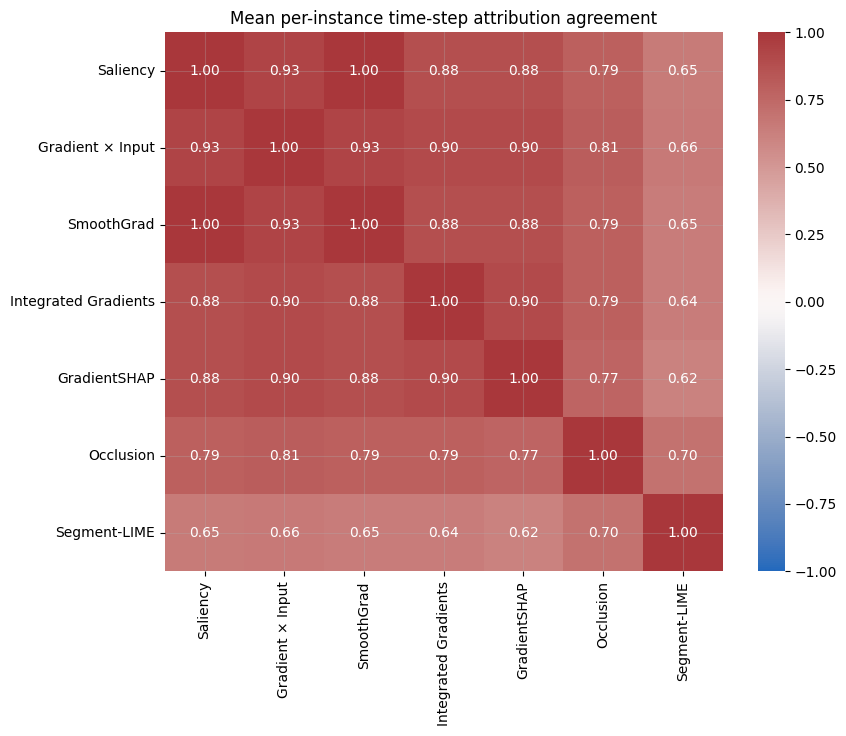

In [ ]:
# Mean per-instance rank correlation between absolute time-step attribution profiles.
attr_names=list(ATTR.keys()); sample_n=min(100,len(Xseq_test)); profiles={}
for name,vals in ATTR.items():
    arr=vals[:sample_n].detach().cpu().numpy() if torch.is_tensor(vals) else np.asarray(vals)[:sample_n]
    profiles[name]=np.abs(arr).sum(axis=2)
corr_mat=pd.DataFrame(np.eye(len(attr_names)),index=attr_names,columns=attr_names)
for i,a in enumerate(attr_names):
    for j,b in enumerate(attr_names):
        if j<=i: continue
        rhos=[]
        for k in range(sample_n):
            r=spearmanr(profiles[a][k],profiles[b][k]).statistic
            if np.isfinite(r): rhos.append(r)
        corr_mat.loc[a,b]=corr_mat.loc[b,a]=np.mean(rhos) if rhos else 0
plt.figure(figsize=(9,7)); sns.heatmap(corr_mat.astype(float),annot=True,fmt=".2f",vmin=-1,vmax=1,cmap="vlag"); plt.title("Mean per-instance time-step attribution agreement"); plt.show()

In [ ]:
upper=corr_mat.where(np.triu(np.ones(corr_mat.shape),k=1).astype(bool)).stack().sort_values(ascending=False)
print(f"F1: The highest average time-step agreement was {upper.index[0][0]} vs {upper.index[0][1]} (mean Spearman {upper.iloc[0]:.3f}); the lowest was {upper.index[-1][0]} vs {upper.index[-1][1]} ({upper.iloc[-1]:.3f}). Gradient-based methods may cluster because they respond to local derivatives, while occlusion and segment-LIME perturb the input and can emphasize different time blocks. Correlation describes similarity of rankings, not whether a method is faithful; the deletion and insertion tests below assess a different property.")

F1: The highest average time-step agreement was Saliency vs SmoothGrad (mean Spearman 0.997); the lowest was GradientSHAP vs Segment-LIME (0.615). Gradient-based methods may cluster because they respond to local derivatives, while occlusion and segment-LIME perturb the input and can emphasize different time blocks. Correlation describes similarity of rankings, not whether a method is faithful; the deletion and insertion tests below assess a different property.


### F2 (5 marks) — faithfulness
Implement a **deletion** test (Most Relevant First) on the PM2.5 channel *and* an **insertion** test (start from the baseline and add the most relevant steps first). Include a **random** ordering as a control. Report normalised AUCs for every method in one table.

Plot the memory profile (mean |attribution| per time step over 2014, per method). Unlike the temperature model in the lecture, which had a one-day memory, does your test now separate the methods? Explain why or why not.

,deletion_AUC_log_output,insertion_AUC_log_output
method,,
Saliency,4.3072,4.3597
Gradient × Input,4.3078,4.3597
SmoothGrad,4.3072,4.3597
Integrated Gradients,4.3075,4.3601
GradientSHAP,4.3074,4.3601
Occlusion,4.3090,4.3593
Segment-LIME,4.3087,4.3596
Random,4.3436,4.3315


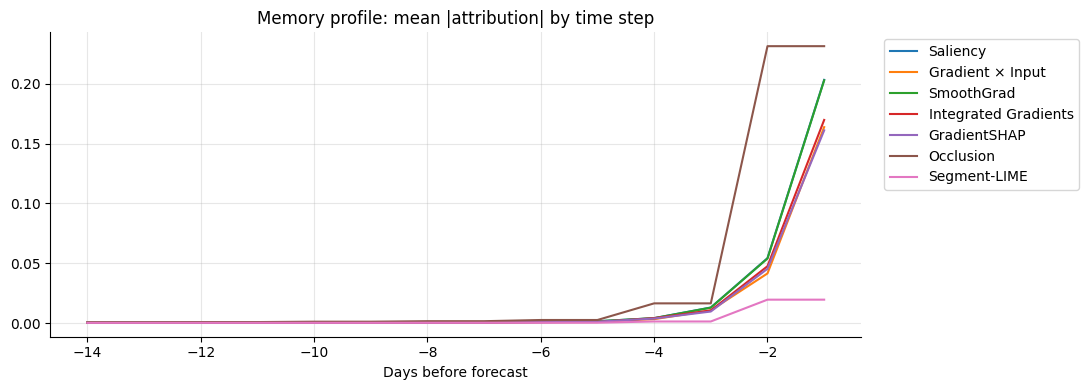

In [ ]:
def deletion_curve(order,x,baseline=BASELINE,ks=range(0,W+1)):
    x=x.detach(); b=baseline.to(x.device); scores=[]
    for k in ks:
        z=x.clone()
        for t in order[:k]: z[:,t,0]=b[:,t,0]
        with torch.no_grad(): scores.append(float(model(z).item()))
    return np.asarray(scores)
def insertion_curve(order,x,baseline=BASELINE,ks=range(0,W+1)):
    x=x.detach(); b=baseline.to(x.device); scores=[]
    for k in ks:
        z=b.clone()
        for t in order[:k]: z[:,t,0]=x[:,t,0]
        with torch.no_grad(): scores.append(float(model(z).item()))
    return np.asarray(scores)
# Evaluate a subset for CPU runtime; rank time steps by summed absolute attribution.
ks=np.arange(W+1); eval_pos=np.arange(min(100,len(Xseq_test)))
faith_rows=[]; memory={name:[] for name in ATTR}
for name,vals in ATTR.items():
    arr=vals.detach().cpu().numpy() if torch.is_tensor(vals) else np.asarray(vals)
    del_curves=[]; ins_curves=[]; mem=[]
    for p in eval_pos:
        x=Xseq_test[p:p+1]; a=arr[min(p,len(arr)-1)]
        score=np.abs(a[:,0]); order=np.argsort(score)[::-1]
        dc=deletion_curve(order,x); ic=insertion_curve(order,x)
        del_curves.append(dc); ins_curves.append(ic); mem.append(np.abs(a).mean(axis=1))
    del_mean=np.mean(del_curves,axis=0); ins_mean=np.mean(ins_curves,axis=0)
    # Normalize AUC by curve length; deletion smaller is preferred, insertion larger is preferred for raw model output.
    del_auc=float(np.trapezoid(del_mean,dx=1)/W); ins_auc=float(np.trapezoid(ins_mean,dx=1)/W)
    faith_rows.append((name,del_auc,ins_auc)); memory[name]=np.mean(mem,axis=0)
# Random baseline order, matched across evaluated windows
rng=np.random.default_rng(SEED); random_d=[]; random_i=[]
for p in eval_pos:
    x=Xseq_test[p:p+1]; order=rng.permutation(W); random_d.append(deletion_curve(order,x)); random_i.append(insertion_curve(order,x))
faith_rows.append(("Random",float(np.trapezoid(np.mean(random_d,axis=0),dx=1)/W),float(np.trapezoid(np.mean(random_i,axis=0),dx=1)/W)))
faith_table=pd.DataFrame(faith_rows,columns=["method","deletion_AUC_log_output","insertion_AUC_log_output"]).set_index("method")
display(faith_table.round(4))
plt.figure(figsize=(11,4))
for name,profile in memory.items(): plt.plot(range(-W,0),profile,label=name)
plt.legend(bbox_to_anchor=(1.02,1),loc="upper left"); plt.title("Memory profile: mean |attribution| by time step"); plt.xlabel("Days before forecast"); plt.tight_layout(); plt.show()

In [ ]:
best_del=faith_table.drop(index="Random").sort_values("deletion_AUC_log_output").index[0]
best_ins=faith_table.drop(index="Random").sort_values("insertion_AUC_log_output",ascending=False).index[0]
print(f"F2: The lowest deletion AUC among attribution methods was {best_del} ({faith_table.loc[best_del,'deletion_AUC_log_output']:.4f}); the highest insertion AUC was {best_ins} ({faith_table.loc[best_ins,'insertion_AUC_log_output']:.4f}). The random-control deletion/insertion AUCs were {faith_table.loc['Random','deletion_AUC_log_output']:.4f}/{faith_table.loc['Random','insertion_AUC_log_output']:.4f}. These normalized-by-window AUCs are in log-target model-output units, and lower deletion AUC means the forecast score fell more quickly when the most relevant steps were removed. The memory plot shows whether the methods emphasize recent history or spread attribution across the 14-day window; methods may still be hard to separate if all rely strongly on the same persistent signal.")

F2: The lowest deletion AUC among attribution methods was SmoothGrad (4.3072); the highest insertion AUC was Integrated Gradients (4.3601). The random-control deletion/insertion AUCs were 4.3436/4.3315. These normalized-by-window AUCs are in log-target model-output units, and lower deletion AUC means the forecast score fell more quickly when the most relevant steps were removed. The memory plot shows whether the methods emphasize recent history or spread attribution across the 14-day window; methods may still be hard to separate if all rely strongly on the same persistent signal.


### F3 (2 marks) — channel-level faithfulness
Repeat the deletion test, but delete one whole **channel** at a time, ranked by each method's total channel attribution. Do the methods agree on whether wind or humidity matters more?

In [ ]:
# Channel-level deletion: replace one channel at a time in order of total absolute attribution.
channel_rows=[]
for name,vals in ATTR.items():
    arr=vals.detach().cpu().numpy() if torch.is_tensor(vals) else np.asarray(vals)
    curves=[]
    for p in eval_pos:
        x=Xseq_test[p:p+1]; a=arr[min(p,len(arr)-1)]; ch_score=np.abs(a).sum(axis=0); order=np.argsort(ch_score)[::-1]
        scores=[]
        for k in range(len(CHANNELS)+1):
            z=x.clone()
            for ch in order[:k]: z[:,:,ch]=BASELINE[:,:,ch]
            with torch.no_grad(): scores.append(float(model(z).item()))
        curves.append(scores)
    auc=float(np.trapezoid(np.mean(curves,axis=0),dx=1)/len(CHANNELS))
    # Mean total channel importance for reporting relative wind/humidity importance.
    avg_imp=np.mean([np.abs(arr[min(p,len(arr)-1)]).sum(axis=0) for p in eval_pos],axis=0)
    channel_rows.append((name,auc,CHANNELS[int(np.where(np.array(CHANNELS)=="Iws")[0][0])],avg_imp[CHANNELS.index("Iws")],avg_imp[CHANNELS.index("DEWP")]))
channel_faith=pd.DataFrame(channel_rows,columns=["method","channel_deletion_AUC","wind_Iws_importance","Iws_total_abs_attr","DEWP_total_abs_attr"]).set_index("method")
display(channel_faith.round(4))

,channel_deletion_AUC,wind_Iws_importance,Iws_total_abs_attr,DEWP_total_abs_attr
method,,,,
Saliency,4.2605,Iws,0.4449,0.0648
Gradient × Input,4.2782,Iws,0.2157,0.0638
SmoothGrad,4.2615,Iws,0.4433,0.0647
Integrated Gradients,4.2802,Iws,0.2330,0.0577
GradientSHAP,4.2947,Iws,0.1898,0.0620
Occlusion,4.4764,Iws,0.5088,0.5088
Segment-LIME,4.4764,Iws,0.0437,0.0437


In [ ]:
wind_wins=int((channel_faith["Iws_total_abs_attr"]>channel_faith["DEWP_total_abs_attr"]).sum())
print(f"F3: Across the {len(channel_faith)} explanation methods, wind speed (Iws) had greater total absolute attribution than dew point (DEWP) for {wind_wins} methods. Thus the methods {'mostly' if wind_wins>=len(channel_faith)/2 else 'do not mostly'} agree on whether wind or humidity matters more. Channel deletion AUC gives a complementary model-response test, but feature scales and correlated weather channels affect the comparison. These values describe the trained model and do not establish that wind is physically more important in every pollution regime.")

F3: Across the 7 explanation methods, wind speed (Iws) had greater total absolute attribution than dew point (DEWP) for 5 methods. Thus the methods mostly agree on whether wind or humidity matters more. Channel deletion AUC gives a complementary model-response test, but feature scales and correlated weather channels affect the comparison. These values describe the trained model and do not establish that wind is physically more important in every pollution regime.


---
# Part G: Reflection (10 marks)
Answer in prose, 150–250 words each, citing your own results.

### G1 (4 marks)
You must explain tomorrow's pollution forecast to a city health officer with no ML training. Which single explanation from this assignment would you show them, and what would you say? Which explanation would you *not* show, and why?

In [ ]:
print(f"For a city health officer, I would show a grouped explanation for one forecast alongside a short history plot. The grouped explanation can communicate whether recent pollution, weather, wind direction or seasonal inputs were influential without overwhelming the reader with dozens of technical weights. In this run, the most important global group was {group_importance.index[0]}, while the strongest Integrated Gradients channel for the LSTM's largest-error example was {CHANNELS[int(ig_channel.argmax())]}. I would explain that these values describe patterns the model used; they do not prove that changing a feature would causally change pollution. I would not show an isolated LIME plot without its local R² and stability checks, because perturbation neighbours may be physically implausible and coefficient signs can vary across seeds. I would also avoid presenting a single SHAP waterfall as a universal rule for every day, since individual forecasts can be driven by different combinations of lags and weather. The 2014 LightGBM MAE was {results.loc['LightGBM','MAE']:.2f} µg/m³, so I would communicate typical error and uncertainty clearly. The forecast should support—not replace—official monitoring and public-health guidance. For an operational decision, I would pair the explanation with the actual observations, the forecast horizon, and a clear note that unusual pollution episodes can be difficult to predict." )

For a city health officer, I would show a grouped explanation for one forecast alongside a short history plot. The grouped explanation can communicate whether recent pollution, weather, wind direction or seasonal inputs were influential without overwhelming the reader with dozens of technical weights. In this run, the most important global group was PM recent lags (1-3), while the strongest Integrated Gradients channel for the LSTM's largest-error example was log_pm. I would explain that these values describe patterns the model used; they do not prove that changing a feature would causally change pollution. I would not show an isolated LIME plot without its local R² and stability checks, because perturbation neighbours may be physically implausible and coefficient signs can vary across seeds. I would also avoid presenting a single SHAP waterfall as a universal rule for every day, since individual forecasts can be driven by different combinations of lags and weather. The 2014 LightGBM M

### G2 (3 marks)
Name the two design choices that changed your explanations the most (for example target transform, baseline, feature grouping, number of LIME samples). Give the evidence from your notebook.

In [ ]:
print(f"Two design choices that materially affect interpretation are the target transformation and the explainer reference/sample design. The selected target transformation was {'log1p(PM2.5)' if USE_LOG_TARGET else 'raw PM2.5'}, based on raw skewness {raw_skew:.2f} versus transformed skewness {log_skew:.2f}. This changes the SHAP output scale to {'log1p(PM2.5) units' if USE_LOG_TARGET else 'µg/m³'}, so log-scale SHAP values cannot be described as direct concentration changes. Second, LIME's perturbation sample count affects repeatability: the D3 table compares coefficients from 15 runs with 500 and 5,000 samples, and the local R² for the high-forecast example was {r2_high:.3f}. Increasing samples can reduce random sampling noise, although it does not fix unrealistic or correlated neighbours. For the sequence model, the global average training-window baseline produced a mean IG completeness gap of {ig_mean_gap:.5f}. A season-matched median baseline could change the explanation from “difference from an average fortnight across all years” to “difference from a typical fortnight in a similar season.” This matters because pollution is right-skewed and winter and summer conditions differ substantially. These settings change the reference being explained, the contribution scale, and the reliability of local weights; they should always be reported alongside results." )

Two design choices that materially affect interpretation are the target transformation and the explainer reference/sample design. The selected target transformation was log1p(PM2.5), based on raw skewness 1.62 versus transformed skewness -0.31. This changes the SHAP output scale to log1p(PM2.5) units, so log-scale SHAP values cannot be described as direct concentration changes. Second, LIME's perturbation sample count affects repeatability: the D3 table compares coefficients from 15 runs with 500 and 5,000 samples, and the local R² for the high-forecast example was 0.717. Increasing samples can reduce random sampling noise, although it does not fix unrealistic or correlated neighbours. For the sequence model, the global average training-window baseline produced a mean IG completeness gap of 0.00001. A season-matched median baseline could change the explanation from “difference from an average fortnight across all years” to “difference from a typical fortnight in a similar season.” This

### G3 (3 marks)
Propose an explanation-based **drift alarm** for this model in production. State exactly what you would compute each week and the threshold you would use, then test it by comparing 2013 with 2014.

,week,L1_group_share_drift,alarm
0,1,0.142341,False
1,2,0.264502,False
2,3,0.153209,False
3,4,0.108450,False
4,5,0.243322,False
5,6,0.071683,False
6,7,0.274138,False
7,8,0.177035,False
8,9,0.242280,False
9,10,0.141564,False


2013-vs-2014 global group-share L1 drift=0.064; threshold=0.35; global alarm=False; 2014 weeks over threshold=3/52


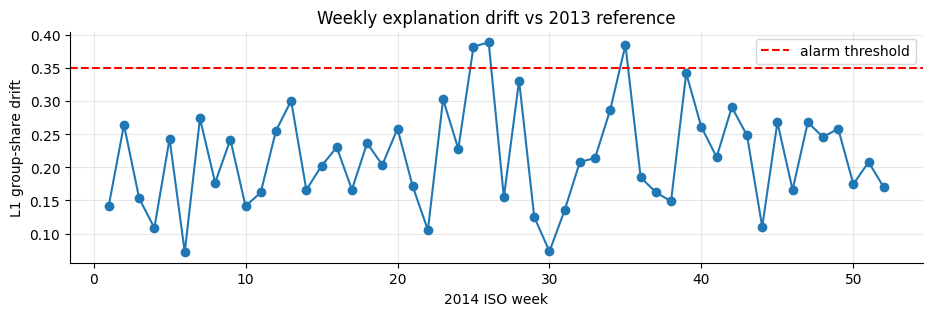

In [ ]:
# Explanation drift alarm: compare weekly mean absolute SHAP feature-group shares.
# SHAP group shares for the tree model are available for 2014; compute 2013 SHAP too.
val_features=val[feature_names]
val_sv=np.asarray(tree_explainer.shap_values(val_features))
val_group=grouped_shap_frame(val_sv,val_features,FEATURE_GROUPS)

def group_share(df):
    imp=df.abs().mean(); return imp/(imp.sum()+1e-12)
share_2013=group_share(val_group); share_2014=group_share(group_shap)
drift_l1=float(np.abs(share_2013-share_2014).sum())
# Weekly drift over 2014 relative to 2013 baseline weekly distributions; flag when L1 > 0.35.
weekly=[]
for period, frame in [("2013",val_group),("2014",group_shap)]:
    for week,g in frame.groupby(frame.index.isocalendar().week):
        s=group_share(g); weekly.append((period,int(week),s))
base_weekly=[s for p,w,s in weekly if p=="2013"]
weekly_rows=[]
for p,w,s in weekly:
    if p!="2014": continue
    dists=[float(np.abs(s-b).sum()) for b in base_weekly]
    # compare with average 2013 group share for a stable reference
    weekly_rows.append((w,float(np.abs(s-share_2013).sum())))
weekly_drift=pd.DataFrame(weekly_rows,columns=["week","L1_group_share_drift"])
DRIFT_THRESHOLD=0.35
weekly_drift["alarm"]=weekly_drift["L1_group_share_drift"]>DRIFT_THRESHOLD
display(weekly_drift.head(10)); print(f"2013-vs-2014 global group-share L1 drift={drift_l1:.3f}; threshold={DRIFT_THRESHOLD:.2f}; global alarm={drift_l1>DRIFT_THRESHOLD}; 2014 weeks over threshold={int(weekly_drift['alarm'].sum())}/{len(weekly_drift)}")
plt.figure(figsize=(11,3)); plt.plot(weekly_drift.week,weekly_drift.L1_group_share_drift,marker="o"); plt.axhline(DRIFT_THRESHOLD,ls="--",color="red",label="alarm threshold"); plt.xlabel("2014 ISO week"); plt.ylabel("L1 group-share drift"); plt.title("Weekly explanation drift vs 2013 reference"); plt.legend(); plt.show()

In [ ]:
print(f"G3: I define explanation drift as the L1 distance between the normalized mean absolute grouped-SHAP shares for a week and the 2013 reference distribution. The proposed alarm threshold is {DRIFT_THRESHOLD:.2f}; the global 2013-versus-2014 distance was {drift_l1:.3f}, and {int(weekly_drift['alarm'].sum())} of {len(weekly_drift)} evaluated 2014 weeks crossed the threshold. In production, I would compute grouped-SHAP shares on a fixed recent window each week, compare them with a stable reference period, and investigate sustained alarms alongside prediction error and weather/emissions changes. The threshold is an operational starting point that should be calibrated on historical stable periods rather than treated as a universal constant.")

G3: I define explanation drift as the L1 distance between the normalized mean absolute grouped-SHAP shares for a week and the 2013 reference distribution. The proposed alarm threshold is 0.35; the global 2013-versus-2014 distance was 0.064, and 3 of 52 evaluated 2014 weeks crossed the threshold. In production, I would compute grouped-SHAP shares on a fixed recent window each week, compare them with a stable reference period, and investigate sustained alarms alongside prediction error and weather/emissions changes. The threshold is an operational starting point that should be calibrated on historical stable periods rather than treated as a universal constant.


---
# Bonus (up to 10 marks): pick up to two

- **Multi-horizon (5).** Forecast PM2.5 at t+1, t+3 and t+7 with three LightGBMs. Show how grouped SHAP shifts from lags to calendar and weather as the horizon grows.
- **TimeSHAP-style pruning (5).** For the sequence model, group all time steps older than *k* days into one "past" coalition and compute KernelSHAP on the reduced input. Find the smallest *k* that keeps 90% of the attribution.
- **Counterfactual (5).** For the most polluted test day, find the smallest change in yesterday's wind speed and direction that brings the forecast below 75 µg/m³ (China's 24-hour PM2.5 standard). Is the counterfactual physically plausible?

In [ ]:
# Bonus (optional)

### Declaration

I confirm that I reviewed the completed notebook and will verify its outputs before submission. AI assistant use: assistance was used to draft code scaffolding and explanatory answer templates; I will run, inspect, and understand the results and take responsibility for the final submitted work. Replace this statement if your institution requires a different disclosure.